In [ ]:
%load_ext tensorboard

import tensorflow as tf
import tensorflow_io as tfio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import display
import seaborn as sns
import datetime
import json
import os

# This notebook lives in HostSW/Notebooks; all paths below are relative to HostSW
if os.path.basename(os.getcwd()) == "Notebooks":
    os.chdir("..")

from tensorflow.keras import layers
from tensorflow.keras import models

# Set the seed value for experiment reproducibility.
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

# Model version: names the checkpoint/TensorBoard dirs, the tflite files and the MLflow run.
MODEL_VERSION = "v10"
# What changed in this version (shown as the MLflow run description)
RUN_NOTES = "Increased number of other words in dataset. Per-word other sampling (~11k), confusable words x4, balanced class weights"

TFLITE_INT8_PATH = f"tflite_models/kws_{MODEL_VERSION}_int8_softmax.tflite"
TFLITE_FLOAT_PATH = f"tflite_models/kws_{MODEL_VERSION}_float32_softmax.tflite"

# Optuna architecture search at the end of the notebook. Slow, so off by default
# and "Run All" stops after the board eval.
RUN_OPTIMIZE = False

# MLflow Tracking

In [2]:
import hashlib
import pathlib
import subprocess
import tempfile
import warnings

import mlflow

# Runs are stored in mlflow/ (see mlflow/README.md): metadata in a SQLite DB with the
# artifacts next to it, so the whole folder can be committed with Git LFS.
# UI: mlflow ui --backend-store-uri sqlite:///mlflow/mlflow.db
MLFLOW_TRACKING_URI = "sqlite:///mlflow/mlflow.db"
MLFLOW_ARTIFACT_DIR = pathlib.Path("mlflow/artifacts")
MLFLOW_EXPERIMENT = "kws"


def init_mlflow():
    os.makedirs("mlflow", exist_ok=True)
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
        # Without an explicit location MLflow puts artifacts in ./mlruns
        mlflow.create_experiment(MLFLOW_EXPERIMENT,
                                 artifact_location=MLFLOW_ARTIFACT_DIR.resolve().as_uri())
    mlflow.set_experiment(MLFLOW_EXPERIMENT)


def require_mlflow_run():
    """Logging with no active run makes MLflow silently start a new, separate run.
    Call this at the top of every logging cell so that fails loudly instead."""
    run = mlflow.active_run()
    if run is None:
        raise RuntimeError("No active MLflow run: run the 'Start MLflow Run' cell first")
    return run


def git_info():
    """Commit + dirty state of the repo. The commit also pins the dataset_board/ (Git LFS) audio."""
    commit = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
    # Untracked files (e.g. scratch captures) don't count as dirty
    status = subprocess.check_output(["git", "status", "--porcelain", "--untracked-files=no"], text=True)
    dirty_files = [line[3:] for line in status.splitlines()]
    return {
        "git_commit": commit,
        "git_dirty": str(bool(dirty_files)),
        "git_dirty_files": ", ".join(dirty_files)[:5000],  # MLflow tag values are length-limited
    }


def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 16), b""):
            h.update(block)
    return h.hexdigest()


init_mlflow()

# Audio Preprocessing Library

## CTypes interface

In [3]:
import ctypes
import numpy as np

# --- Constants matching the C header ---
AUDIO_SPECTROGRAM_FRAME_LEN = 512
AUDIO_SAMPLE_RATE_HZ = 16000
AUDIO_SPECTROGRAM_NMELS = 30
AUDIO_SPECTROGRAM_ROWS = AUDIO_SPECTROGRAM_NMELS
AUDIO_SPECTROGRAM_STRIDE_LEN = 352  # 22 ms at 16000 Hz (16000 * 0.022 = 352)
AUDIO_SPECTROGRAM_COLS = 45          # updated to match 1s clips at this stride
SIGNAL_LEN_1S = AUDIO_SAMPLE_RATE_HZ  # 16000 samples = 1 second

STATUS_OK = 0
STATUS_ERROR_SPECTROGRAM_FULL = 1
STATUS_ERROR_OTHER = 2

class AudioPreprocessingError(RuntimeError):
    pass

class AudioPreprocessor:
    """Thin ctypes wrapper. NOT thread-safe -- use one instance, serially,
    per process. Do not share across threads or call concurrently."""

    def __init__(self, lib_path="./build/audioproc-build/libAudioPreprocessing.dylib"):
        self.lib = ctypes.CDLL(lib_path)
        self._declare_signatures()
        status = self.lib.audio_preprocessing_init()
        if status != STATUS_OK:
            raise AudioPreprocessingError(f"init failed with status {status}")

    def _declare_signatures(self):
        self.lib.audio_preprocessing_init.argtypes = []
        self.lib.audio_preprocessing_init.restype = ctypes.c_int

        self.lib.audio_preprocessing_process_frame.argtypes = [ctypes.POINTER(ctypes.c_float)]
        self.lib.audio_preprocessing_process_frame.restype = ctypes.c_int

        self.lib.audio_preprocessing_get_spectrogram.argtypes = []
        self.lib.audio_preprocessing_get_spectrogram.restype = ctypes.POINTER(ctypes.c_float)

        self.lib.audio_preprocessing_get_spectrogram_len.argtypes = []
        self.lib.audio_preprocessing_get_spectrogram_len.restype = ctypes.c_uint32

        self.lib.audio_preprocessing_get_spectrogram_filled_cols.argtypes = []
        self.lib.audio_preprocessing_get_spectrogram_filled_cols.restype = ctypes.c_uint32

        self.lib.audio_preprocessing_clear_spectrogram.argtypes = []
        self.lib.audio_preprocessing_clear_spectrogram.restype = ctypes.c_int

    def compute_spectrogram(self, signal):
        """
        signal: 1D array-like of raw audio samples, expected to be exactly
        1 second long (16000 samples at 16000 Hz).
    
        Frames are AUDIO_SPECTROGRAM_FRAME_LEN (512, 32ms) samples long,
        advancing by AUDIO_SPECTROGRAM_STRIDE_LEN (352, 22ms) samples each
        step (overlapping frames). This produces exactly
        AUDIO_SPECTROGRAM_COLS (45) frames from a 1s signal:
        floor((16000 - 512) / 352) + 1 == 45.
    
        Returns: np.ndarray of shape (AUDIO_SPECTROGRAM_ROWS, AUDIO_SPECTROGRAM_COLS)
        """
        # np.ascontiguousarray returns the *same* array (no copy) if it's already
        # contiguous float32 -- since the C function modifies its input buffer,
        # we need an explicit copy here so we never mutate the caller's array.
        signal = np.array(signal, dtype=np.float32, copy=True)
        signal = np.ascontiguousarray(signal)
    
        n_frames = (len(signal) - AUDIO_SPECTROGRAM_FRAME_LEN) // AUDIO_SPECTROGRAM_STRIDE_LEN + 1
        if n_frames != AUDIO_SPECTROGRAM_COLS:
            raise ValueError(
                f"signal length {len(signal)} produces {n_frames} frames "
                f"(frame_len={AUDIO_SPECTROGRAM_FRAME_LEN}, stride={AUDIO_SPECTROGRAM_STRIDE_LEN}), "
                f"expected exactly {AUDIO_SPECTROGRAM_COLS}. "
                f"For {AUDIO_SPECTROGRAM_COLS} frames, signal length must be "
                f"{AUDIO_SPECTROGRAM_FRAME_LEN + (AUDIO_SPECTROGRAM_COLS - 1) * AUDIO_SPECTROGRAM_STRIDE_LEN}."
            )
    
        self.lib.audio_preprocessing_clear_spectrogram()
    
        for i in range(n_frames):
            start = i * AUDIO_SPECTROGRAM_STRIDE_LEN
            # Copy each frame into its own buffer before passing to C, since
            # audio_preprocessing_process_frame modifies the buffer it's given.
            # A slice of `signal` is a view, not a copy -- passing that view's
            # pointer directly would let the C call corrupt `signal` itself,
            # which would then corrupt every subsequent overlapping frame drawn
            # from it.
            frame = np.array(signal[start : start + AUDIO_SPECTROGRAM_FRAME_LEN], copy=True)
            frame_ptr = frame.ctypes.data_as(ctypes.POINTER(ctypes.c_float))
            status = self.lib.audio_preprocessing_process_frame(frame_ptr)
            if status != STATUS_OK:
                raise AudioPreprocessingError(
                    f"run() failed at frame {i} with status {status}"
                )
    
        filled = self.lib.audio_preprocessing_get_spectrogram_filled_cols()
        if filled != AUDIO_SPECTROGRAM_COLS:
            raise AudioPreprocessingError(
                f"expected {AUDIO_SPECTROGRAM_COLS} filled columns, got {filled}"
            )
    
        spec_ptr = self.lib.audio_preprocessing_get_spectrogram()
        spec_len = self.lib.audio_preprocessing_get_spectrogram_len()
        flat = np.ctypeslib.as_array(spec_ptr, shape=(spec_len,)).copy()
    
        spectrogram = flat.reshape(AUDIO_SPECTROGRAM_COLS, AUDIO_SPECTROGRAM_ROWS).T
        return spectrogram

## Test Signal

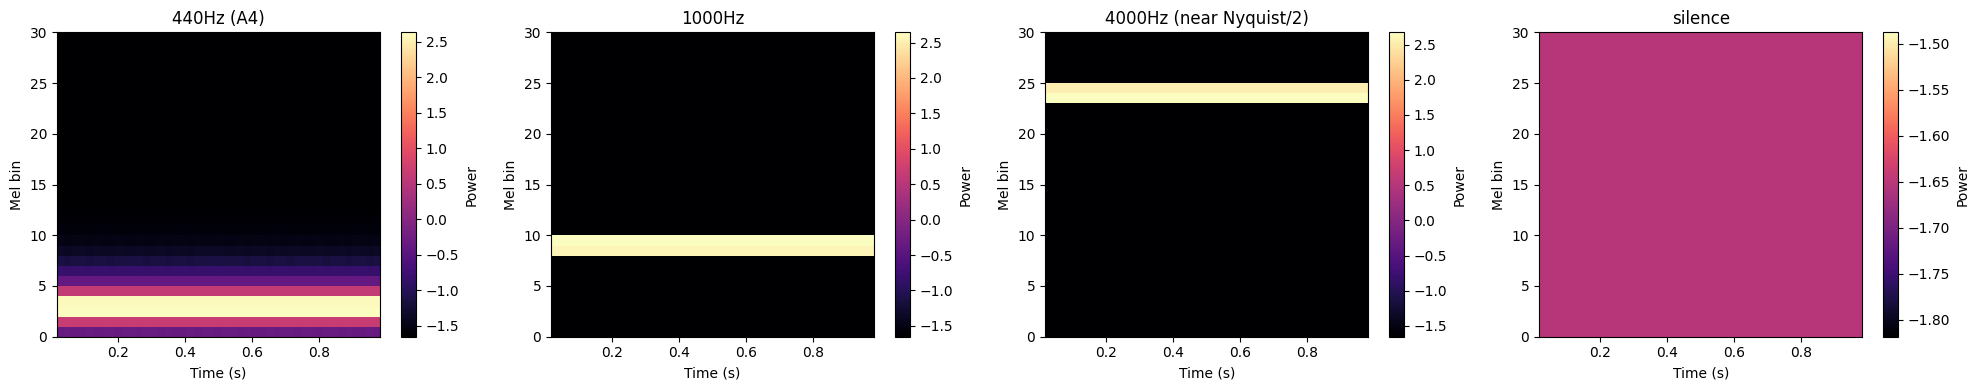


440Hz (A4):
  shape: (30, 45)
  min/max: -1.6530 / 2.6308
  peak mel bin: 2 (of 30)

1000Hz:
  shape: (30, 45)
  min/max: -1.6530 / 2.6442
  peak mel bin: 9 (of 30)

4000Hz (near Nyquist/2):
  shape: (30, 45)
  min/max: -1.6530 / 2.6735
  peak mel bin: 23 (of 30)

silence:
  shape: (30, 45)
  min/max: -1.6530 / -1.6530
  peak mel bin: 0 (of 30)


In [4]:
SIGNAL_LEN = 1 * AUDIO_SAMPLE_RATE_HZ # 1 Second

import matplotlib.pyplot as plt

def make_tone(freq_hz, length=SIGNAL_LEN, sample_rate=AUDIO_SAMPLE_RATE_HZ, amplitude=0.5):
    t = np.arange(length) / sample_rate
    return (amplitude * np.sin(2 * np.pi * freq_hz * t)).astype(np.float32)

AUDIO_SPECTROGRAM_STRIDE_LEN = 352  # 22 ms at 16000 Hz

def plot_spectrogram(spec, title="", sample_rate=AUDIO_SAMPLE_RATE_HZ,
                      frame_len=AUDIO_SPECTROGRAM_FRAME_LEN,
                      stride_len=AUDIO_SPECTROGRAM_STRIDE_LEN, ax=None):
    """
    spec: np.ndarray of shape (n_mels, n_frames), as returned by
    AudioPreprocessor.compute_spectrogram()
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    hop_seconds = stride_len / sample_rate
    n_frames = spec.shape[1]

    # Each column represents a frame_len-sample window starting at i*stride.
    # Label the x-axis by each frame's center time for a more honest
    # representation of overlapping windows -- last frame's window still
    # extends past the final tick, that's expected with overlap.
    frame_center_offset = (frame_len / sample_rate) / 2
    t_start = frame_center_offset
    t_end = (n_frames - 1) * hop_seconds + frame_center_offset
    extent = [t_start, t_end, 0, spec.shape[0]]

    im = ax.imshow(spec, aspect="auto", origin="lower", extent=extent, cmap="magma")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Mel bin")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="Power")
    return ax


def plot_all_test_signals(preproc, test_signals):
    n = len(test_signals)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))
    if n == 1:
        axes = [axes]
    for ax, (name, sig) in zip(axes, test_signals.items()):
        spec = preproc.compute_spectrogram(sig)
        plot_spectrogram(spec, title=name, ax=ax)
    plt.tight_layout()
    plt.show()

def run_test_signal():
    preproc = AudioPreprocessor("./build/audioproc-build/libAudioPreprocessing.dylib")
    
    test_signals = {
        "440Hz (A4)": make_tone(440),
        "1000Hz": make_tone(1000),
        "4000Hz (near Nyquist/2)": make_tone(4000),
        "silence": np.zeros(SIGNAL_LEN, dtype=np.float32),
    }
    
    plot_all_test_signals(preproc, test_signals)
    
    for name, sig in test_signals.items():
        spec = preproc.compute_spectrogram(sig)
        print(f"\n{name}:")
        print(f"  shape: {spec.shape}")
        print(f"  min/max: {spec.min():.4f} / {spec.max():.4f}")
        # which mel bin has the most energy, averaged across time columns
        mean_per_mel = spec.mean(axis=1)
        peak_mel_bin = np.argmax(mean_per_mel)
        print(f"  peak mel bin: {peak_mel_bin} (of {spec.shape[0]})")

run_test_signal()

# Load Dataset

In [5]:
import os.path
import re
import sys
import tarfile

import urllib
import tensorflow as tf

from tensorflow.python.platform import gfile

DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz'
DATA_DIR = './dataset'
FS = 16000

def maybe_download_and_extract_dataset(data_url, dest_directory):
    """Download and extract data set tar file.
    
    If the data set we're using doesn't already exist, this function
    downloads it from the TensorFlow.org website and unpacks it into a
    directory.
    If the data_url is none, don't download anything and expect the data
    directory to contain the correct files already.
    
    Args:
      data_url: Web location of the tar file containing the data set.
      dest_directory: File path to extract data to.
    """
    if not data_url:
        return
    if not gfile.Exists(dest_directory):
        os.makedirs(dest_directory)
    filename = data_url.split('/')[-1]
    filepath = os.path.join(dest_directory, filename)
    if not gfile.Exists(filepath):
    
        def _progress(count, block_size, total_size):
            percent = float(count * block_size) / float(total_size) * 100.0
            # Only print when the integer percentage changes
            if percent - _progress.last_percent >= 1.0 or percent >= 100.0:
                sys.stdout.write('\r>> Downloading %s %.1f%%' % (filename, percent))
                sys.stdout.flush()
                _progress.last_percent = percent


        _progress.last_percent = 0.0
    
        try:
            filepath, _ = urllib.request.urlretrieve(data_url, filepath, _progress)
        except:
            tf.compat.v1.logging.error(
                'Failed to download URL: {0} to folder: {1}. Please make sure you '
                'have enough free space and an internet connection'.format(
                data_url, filepath))
            raise
        print()
        statinfo = os.stat(filepath)
        tf.compat.v1.logging.info(
            'Successfully downloaded {0} ({1} bytes)'.format(
                filename, statinfo.st_size))
        tarfile.open(filepath, 'r:gz').extractall(dest_directory)

maybe_download_and_extract_dataset(DATA_URL, DATA_DIR)

# Preprocess Dataset

## Generate more background noise

Generates 360 s of each colour, but the split cell below only uses the first
`SYNTHETIC_NOISE_SECONDS` of each, so most of the background class is real noise.

In [6]:
"""
Generate colored noise (white, pink, brown, blue, violet) as .wav files.

Colored noise is generated by shaping the frequency spectrum of white
noise with a power law: PSD(f) ~ f^beta

    white   -> beta =  0   (flat spectrum)
    pink    -> beta = -1   (energy falls off as 1/f)
    brown   -> beta = -2   (energy falls off as 1/f^2), aka "red" noise
    blue    -> beta = +1   (energy rises with f)
    violet  -> beta = +2   (energy rises with f^2), aka "purple" noise

This is useful as an augmentation for KWS / audio classification datasets,
since it diversifies the kinds of background noise the model has to be
robust against beyond a single white-noise sample.
"""

import numpy as np
import soundfile as sf
import pathlib

# --- Config ------------------------------------------------------------
DST_DIR = pathlib.Path("dataset/_background_noise_")
SAMPLE_RATE = 16000          # match your existing dataset's sample rate
DURATION_SECONDS = 360        # length of each generated noise file
NOISE_COLORS = {
    "white": 0,
    "pink": -1,
    "brown": -2,
    "blue": 1,
    "violet": 2,
}
SEED = 42  # set to None for non-reproducible output
# -------------------------------------------------------------------------


def generate_colored_noise(n_samples: int, beta: float, rng: np.random.Generator) -> np.ndarray:
    """Generate colored noise of length n_samples with PSD ~ f^beta."""
    # Start from white noise in the frequency domain (random phase + magnitude)
    n_freqs = n_samples // 2 + 1
    white_spectrum = rng.normal(size=n_freqs) + 1j * rng.normal(size=n_freqs)

    # Build the frequency scaling. Avoid division by zero at f=0 (DC term).
    freqs = np.arange(1, n_freqs + 1, dtype=np.float64)
    scale = freqs ** (beta / 2.0)  # sqrt because we're scaling amplitude, not power

    shaped_spectrum = white_spectrum * scale
    shaped_spectrum[0] = 0.0  # zero out DC offset

    # Back to time domain
    noise = np.fft.irfft(shaped_spectrum, n=n_samples)

    # Normalize to [-1, 1] so it's a valid float32 wav signal
    noise = noise / np.max(np.abs(noise))
    return noise.astype(np.float32)


def main():
    DST_DIR.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(SEED)
    n_samples = int(SAMPLE_RATE * DURATION_SECONDS)

    for name, beta in NOISE_COLORS.items():
        out_path = DST_DIR / f"{name}_noise.wav"
        
        if pathlib.Path(out_path).exists():
            print(f"Skipping creating {out_path}, exists already")
            continue
            
        noise = generate_colored_noise(n_samples, beta, rng)
        
        sf.write(out_path, noise, SAMPLE_RATE)
        print(f"Wrote {out_path} ({DURATION_SECONDS}s, beta={beta})")


if __name__ == "__main__":
    main()

Skipping creating dataset/_background_noise_/white_noise.wav, exists already
Skipping creating dataset/_background_noise_/pink_noise.wav, exists already
Skipping creating dataset/_background_noise_/brown_noise.wav, exists already
Skipping creating dataset/_background_noise_/blue_noise.wav, exists already
Skipping creating dataset/_background_noise_/violet_noise.wav, exists already


## Split background noise (Speech Commands + board recordings) into 1 second pieces

In [7]:
"""
Split long background-noise recordings into exactly 1-second chunks for the
_background_noise_ class, saving them to dataset/_background_noise_split_/.

Sources (NOISE_SOURCES):
  dataset/_background_noise_/        Speech Commands noise + generated coloured noise
  dataset_board/_background_noise_/  noise recorded on the board mic (Git LFS)

Synthetic coloured noise (SYNTHETIC_NOISE_STEMS, incl. Speech Commands' own
white/pink files) is capped at SYNTHETIC_NOISE_SECONDS per colour, so the
class is mostly real noise.

Output naming: <source>__<original_stem>_<chunk_index>.wav
e.g. "board__board_room_01_12.wav". The split dir is derived data and is
rebuilt from scratch every time this cell runs, so it always matches the
sources and settings above.

Leftover audio shorter than 1 second at the end of a file is dropped, so
every chunk is exactly the same length.
"""

import shutil

import soundfile as sf
from pathlib import Path

# --- Config ---------------------------------------------------------------
NOISE_SOURCES = {
    "sc": Path("dataset/_background_noise_"),
    "board": Path("dataset_board/_background_noise_"),
}
DST_DIR = Path("dataset/_background_noise_split_")
CHUNK_SECONDS = 1.0
SYNTHETIC_NOISE_STEMS = {"white_noise", "pink_noise", "brown_noise", "blue_noise", "violet_noise"}
SYNTHETIC_NOISE_SECONDS = 30
# ---------------------------------------------------------------------------


def split_wav_file(wav_path: Path, dst_dir: Path, prefix: str, chunk_seconds: float = 1.0,
                   max_chunks: int | None = None) -> int:
    """Split a single wav file into fixed-length chunks. Returns chunk count."""
    audio, sample_rate = sf.read(wav_path, always_2d=False)
    if audio.ndim > 1:
        audio = audio[:, 0]
    if sample_rate != 16000:
        raise ValueError(f"{wav_path}: {sample_rate} Hz, expected 16000 Hz")

    chunk_len = int(round(chunk_seconds * sample_rate))
    n_chunks = len(audio) // chunk_len
    if max_chunks is not None:
        n_chunks = min(n_chunks, max_chunks)

    for i in range(n_chunks):
        chunk = audio[i * chunk_len : (i + 1) * chunk_len]
        sf.write(dst_dir / f"{prefix}__{wav_path.stem}_{i}.wav", chunk, sample_rate, subtype="PCM_16")
    return n_chunks


def main():
    if DST_DIR.is_dir():
        shutil.rmtree(DST_DIR)
    DST_DIR.mkdir(parents=True)

    totals = {"real": 0, "synthetic": 0}
    for prefix, src_dir in NOISE_SOURCES.items():
        wav_files = sorted(src_dir.glob("*.wav"))
        if not wav_files:
            print(f"[warn] no .wav files in {src_dir.resolve()}")
            continue
        for wav_path in wav_files:
            synthetic = wav_path.stem in SYNTHETIC_NOISE_STEMS
            max_chunks = int(SYNTHETIC_NOISE_SECONDS / CHUNK_SECONDS) if synthetic else None
            n_chunks = split_wav_file(wav_path, DST_DIR, prefix, CHUNK_SECONDS, max_chunks)
            totals["synthetic" if synthetic else "real"] += n_chunks
            print(f"{prefix}/{wav_path.name}: {n_chunks} chunks" + (" (synthetic, capped)" if synthetic else ""))

    total = sum(totals.values())
    print(f"\nDone. Wrote {total} chunks to {DST_DIR.resolve()}: "
          f"{totals['real']} real, {totals['synthetic']} synthetic ({100 * totals['synthetic'] / total:.0f}%)")


main()

sc/blue_noise.wav: 30 chunks (synthetic, capped)
sc/brown_noise.wav: 30 chunks (synthetic, capped)
sc/doing_the_dishes.wav: 95 chunks
sc/dude_miaowing.wav: 61 chunks
sc/exercise_bike.wav: 61 chunks
sc/pink_noise.wav: 30 chunks (synthetic, capped)
sc/running_tap.wav: 61 chunks
sc/violet_noise.wav: 30 chunks (synthetic, capped)
sc/white_noise.wav: 30 chunks (synthetic, capped)
board/board_room_01.wav: 226 chunks
board/board_room_02.wav: 345 chunks

Done. Wrote 999 chunks to /Users/gerald/SoftwareProjects/KeywordSpottingFWAI/HostSW/dataset/_background_noise_split_: 849 real, 150 synthetic (15%)


## Split dataset based on new keywords

### Subsample `other` per word

In [8]:
def subsample_other_by_word(files, labels, class_names, group_ids, other_label,
                            clips_per_word, confusable_words=(), confusable_clips_per_word=None,
                            seed=0):
    """
    Subsample the 'other' class per original word: keep up to `clips_per_word`
    random clips of each non-keyword word, or `confusable_clips_per_word` for words
    in `confusable_words` (ones that sound like a keyword). All desired-class
    samples are kept.

    Picks individual clips rather than whole speakers, so 'other' gets as many
    different voices as possible. That doesn't leak speakers across splits: the
    group-aware split after this still keeps each speaker in a single split.

    Returns filtered (files, labels, class_names, group_ids), plus the keep_mask used.
    """
    rng = np.random.default_rng(seed=seed)

    keep_mask = labels != other_label
    print(f"Desired-class samples: {keep_mask.sum()}")

    other_words = np.unique(class_names[labels == other_label])
    unknown = set(confusable_words) - set(other_words)
    if unknown:
        raise ValueError(f"Confusable words not in the 'other' class: {sorted(unknown)}")

    for word in other_words:
        word_idx = np.flatnonzero((class_names == word) & (labels == other_label))
        # Sort by file name so the pick doesn't depend on directory listing order
        word_idx = word_idx[np.argsort(files[word_idx])]
        confusable = word in confusable_words
        cap = confusable_clips_per_word if confusable else clips_per_word
        kept = rng.choice(word_idx, size=min(cap, len(word_idx)), replace=False)
        keep_mask[kept] = True
        print(f"  {word:>8}: {len(kept):5d} of {len(word_idx)}" + (" (confusable)" if confusable else ""))

    filtered_labels = labels[keep_mask]
    actual_other = (filtered_labels == other_label).sum()
    print(f"'other' samples after subsampling: {actual_other} (of {(labels == other_label).sum()})")
    print(f"Total samples after subsampling: {len(filtered_labels)} "
          f"('other' fraction = {actual_other / len(filtered_labels):.3f})")

    return files[keep_mask], filtered_labels, class_names[keep_mask], group_ids[keep_mask], keep_mask

### Split

In [9]:
import pathlib
import re
import numpy as np
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
import tensorflow as tf

DATA_DIR = pathlib.Path(DATA_DIR)

# Board-mic recordings (see dataset_board/README.md). Word clips go in class dirs
# named like the Speech Commands ones; long background recordings in its
# _background_noise_/ dir are split by the cell above, so they're skipped here.
BOARD_DATA_DIR = pathlib.Path('dataset_board')

IGNORE_DIRS = ['_background_noise_']

# Background chunks are grouped in blocks of this many consecutive seconds, so
# neighbouring seconds of one recording (which sound almost the same) can't end
# up on both sides of the train/test split.
BACKGROUND_GROUP_SECONDS = 10

# 'other' keeps up to OTHER_CLIPS_PER_WORD random clips of each non-keyword word, and
# CONFUSABLE_CLIPS_PER_WORD of words that sound like a keyword. Class weights (see
# 'Class Weights') stop the bigger 'other' class from pulling keyword recall down.
# SPLIT_SEED seeds the subsampling and the train/val/test split.
OTHER_CLIPS_PER_WORD = 250
CONFUSABLE_CLIPS_PER_WORD = 1000
CONFUSABLE_WORDS = ['four', 'follow', 'bed', 'bird']  # sound like forward / backward
SPLIT_SEED = 0

# 1. List every file with its original class name + participant id
all_files = []
all_class_names = []
all_group_ids = []

class_dirs = sorted(DATA_DIR.iterdir())
if BOARD_DATA_DIR.is_dir():
    class_dirs += sorted(BOARD_DATA_DIR.iterdir())

for class_dir in class_dirs:
    if not class_dir.is_dir():
        continue
    if class_dir.name in IGNORE_DIRS:
        print(f'Skipping dir {class_dir.name}, in IGNORE_DIRS')
        continue

    for f in sorted(class_dir.glob('*.wav')):
        if class_dir.name == '_background_noise_split_':
            class_name = '_background_noise_'
        else:
            class_name = class_dir.name

        
        all_files.append(str(f))
        all_class_names.append(class_name)

        if class_name == '_background_noise_':
            # No participant id. Chunks are named <source>__<recording>_<index>:
            # group them in BACKGROUND_GROUP_SECONDS blocks of the same recording.
            recording, chunk_idx = f.stem.rsplit('_', 1)
            group_id = f"{recording}_{int(chunk_idx) // BACKGROUND_GROUP_SECONDS}"
        else:
            # Filename like 3b3d2f59_nohash_2.wav -> participant id is the first token
            # (board clips: <session>_<n>.wav -> the session is the group)
            group_id = f.stem.split('_')[0]

        all_group_ids.append(group_id)

all_files = np.array(all_files)
all_class_names = np.array(all_class_names)
all_group_ids = np.array(all_group_ids)

label_names = np.array(sorted(set(all_class_names)))
class_to_idx = {name: i for i, name in enumerate(label_names)}
orig_labels = np.array([class_to_idx[c] for c in all_class_names])

# 2. Build your mapping exactly as before
DESIRED_KEYWORDS = ['forward', 'backward', 'stop']
DESIRED_KEYWORDS.append('_background_noise_')
OTHER_LABEL = len(DESIRED_KEYWORDS)

mapping = np.full(len(label_names), OTHER_LABEL, dtype=np.int64)
for orig_idx, name in enumerate(label_names):
    if name in DESIRED_KEYWORDS:
        mapping[orig_idx] = DESIRED_KEYWORDS.index(name)

new_labels = mapping[orig_labels]

# 3. Subsample 'other' per word

all_files, new_labels, all_class_names, all_group_ids, _ = subsample_other_by_word(
    all_files, new_labels, all_class_names, all_group_ids,
    other_label=OTHER_LABEL,
    clips_per_word=OTHER_CLIPS_PER_WORD,
    confusable_words=CONFUSABLE_WORDS,
    confusable_clips_per_word=CONFUSABLE_CLIPS_PER_WORD,
    seed=SPLIT_SEED)

# 4. Group-aware, label-stratified 3-way split
# StratifiedGroupKFold keeps each group entirely within one fold while
# also trying to balance label proportions across folds.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)  # ~20% per fold
train_idx, temp_idx = next(sgkf.split(all_files, new_labels, groups=all_group_ids))

# Split temp_idx again into val/test, still respecting groups
temp_files = all_files[temp_idx]
temp_labels = new_labels[temp_idx]
temp_groups = all_group_ids[temp_idx]

sgkf2 = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SPLIT_SEED)
val_sub_idx, test_sub_idx = next(sgkf2.split(temp_files, temp_labels, groups=temp_groups))

train_files, train_labels = all_files[train_idx], new_labels[train_idx]
val_files, val_labels = temp_files[val_sub_idx], temp_labels[val_sub_idx]
test_files, test_labels = temp_files[test_sub_idx], temp_labels[test_sub_idx]

# 5. Sanity checks
def summarize(name, files, labels, groups):
    print(f"{name}: {len(files)} files, label dist = {dict(zip(*np.unique(labels, return_counts=True)))}")

summarize("train", train_files, train_labels, all_group_ids[train_idx])
summarize("val", val_files, val_labels, temp_groups[val_sub_idx])
summarize("test", test_files, test_labels, temp_groups[test_sub_idx])

# Confirm no participant overlap across splits (excluding background noise's synthetic per-file groups)
train_groups = set(all_group_ids[train_idx])
val_groups = set(temp_groups[val_sub_idx])
test_groups = set(temp_groups[test_sub_idx])
print("train/val overlap:", train_groups & val_groups)
print("train/test overlap:", train_groups & test_groups)
print("val/test overlap:", val_groups & test_groups)

# Labels
new_label_names = np.array(DESIRED_KEYWORDS + ['other'])
orig_label_names = label_names
label_names = new_label_names

print("New label names: ", label_names)
print("Orig label names: ", orig_label_names)

Skipping dir _background_noise_, in IGNORE_DIRS
Skipping dir _background_noise_, in IGNORE_DIRS
Desired-keyword samples: 8092
Target 'other' samples (20% of total): 2023 (currently 98736)
Actual 'other' samples after subsampling: 2042
Total samples after subsampling: 10134 ('other' fraction = 0.201)
train: 8220 files, label dist = {np.int64(0): np.int64(1279), np.int64(1): np.int64(1382), np.int64(2): np.int64(3107), np.int64(3): np.int64(829), np.int64(4): np.int64(1623)}
val: 866 files, label dist = {np.int64(0): np.int64(126), np.int64(1): np.int64(125), np.int64(2): np.int64(382), np.int64(3): np.int64(90), np.int64(4): np.int64(143)}
test: 1048 files, label dist = {np.int64(0): np.int64(152), np.int64(1): np.int64(157), np.int64(2): np.int64(383), np.int64(3): np.int64(80), np.int64(4): np.int64(276)}
train/val overlap: set()
train/test overlap: set()
val/test overlap: set()
New label names:  ['forward' 'backward' 'stop' '_background_noise_' 'other']
Orig label names:  ['_backgrou

## Load Preprocessing Lib

In [10]:
preproc = AudioPreprocessor("./build/audioproc-build/libAudioPreprocessing.dylib")

## Audio WAV File Loading

In [11]:
def load_wav(file_path, label):
    audio_binary = tf.io.read_file(file_path)
    audio, _ = tf.audio.decode_wav(audio_binary, desired_channels=1, desired_samples=16000)
    audio = tf.squeeze(audio, axis=-1)  # replaces your old `squeeze` map step
    return audio, label

## Check some spectrograms

2026-10-20 11:48:33.999048: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Pro
2026-10-20 11:48:33.999075: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-10-20 11:48:33.999082: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
I0000 00:00:1792511313.999094  102549 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792511313.999112  102549 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


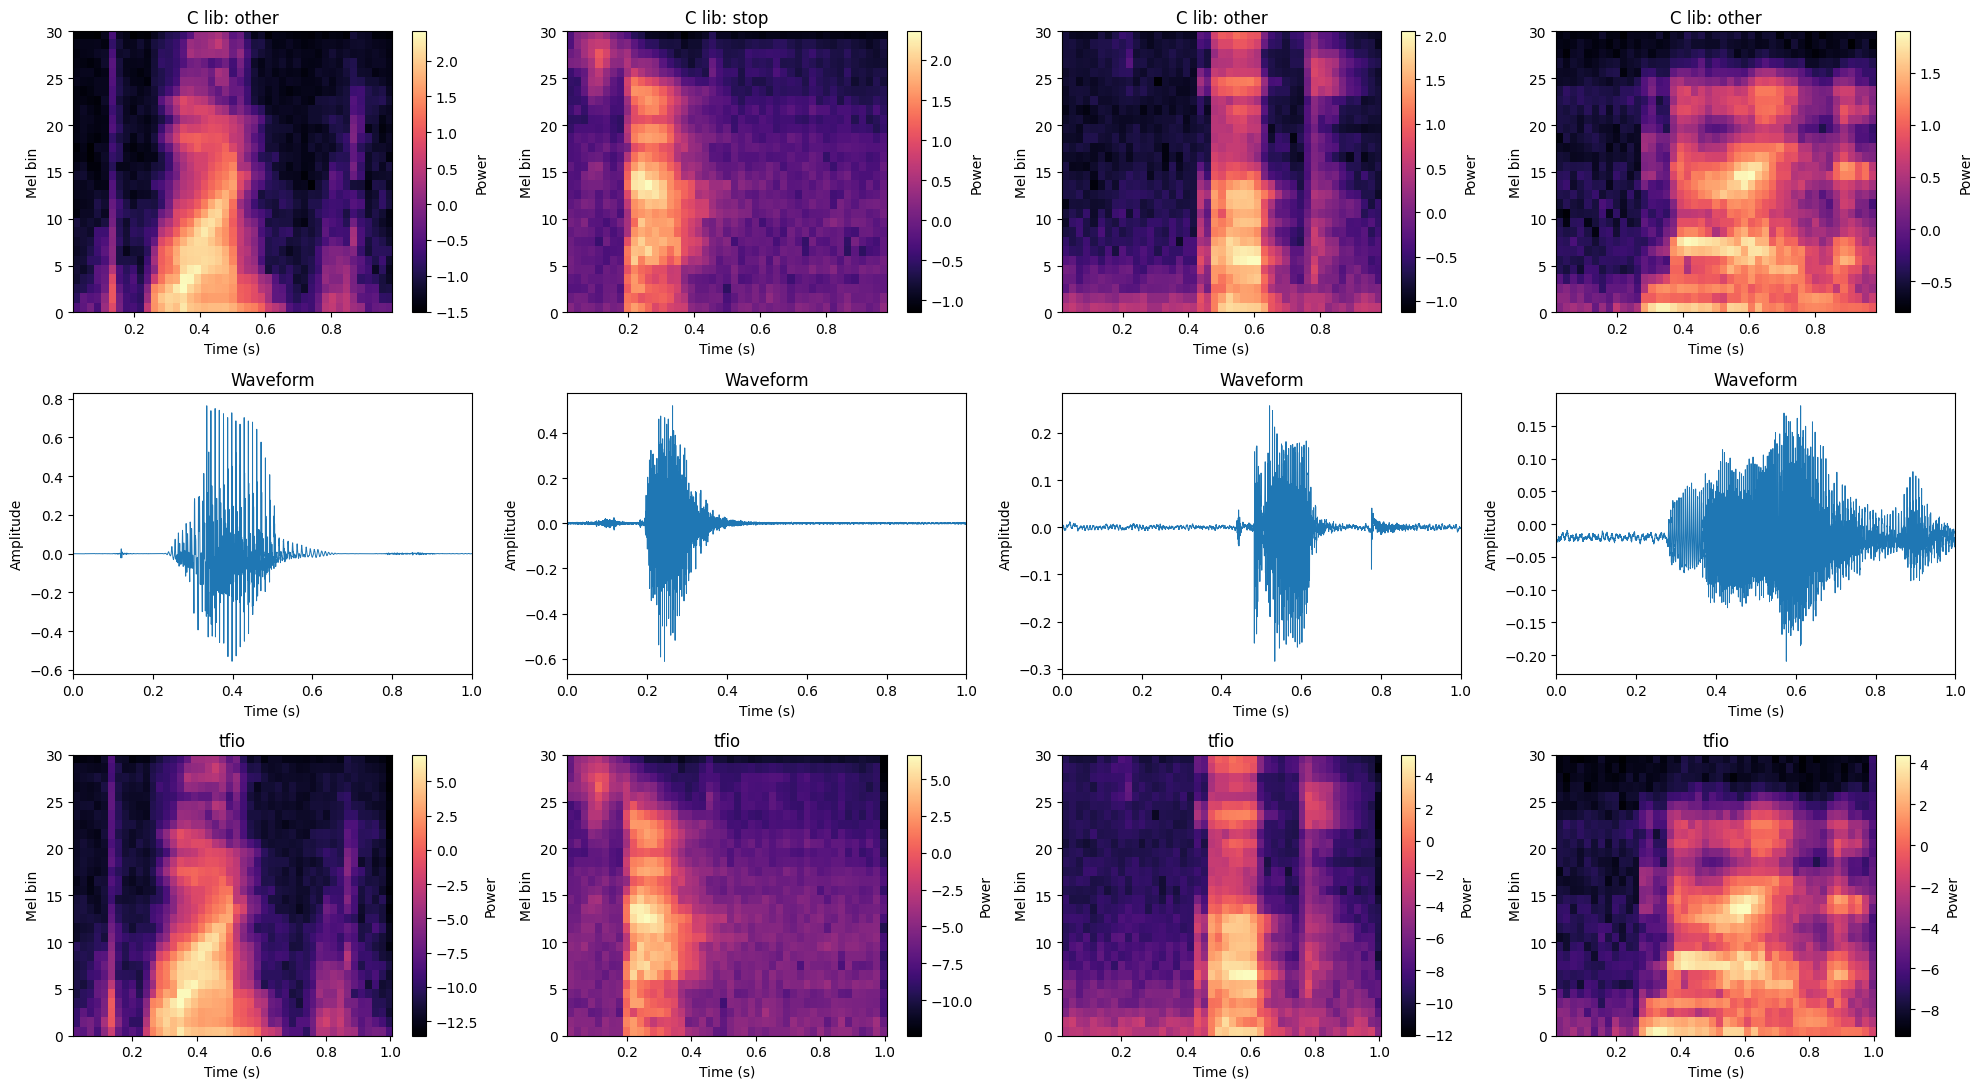

In [12]:
import random
import tensorflow_io as tfio

LOG_EPSILON = 1e-6

def get_spectrogram(waveform):
    return tfio.audio.spectrogram(waveform, nfft=512, window=512, stride=352)
def get_mel_spectrogram(spectrogram, fs):
    return tfio.audio.melscale(spectrogram, rate=fs, mels=30, fmin=125, fmax=7500)

def compare_spectrograms(file_paths, labels, preproc, n_samples=4,
                          label_names=None, seed=None,
                          sample_rate=AUDIO_SAMPLE_RATE_HZ):
    rng = random.Random(seed)
    indices = rng.sample(range(len(file_paths)), n_samples)

    fig, axes = plt.subplots(3, n_samples, figsize=(5 * n_samples, 11))
    if n_samples == 1:
        axes = axes.reshape(3, 1)

    for col, idx in enumerate(indices):
        audio_tensor, label = load_wav(file_paths[idx], labels[idx])
        audio_np = audio_tensor.numpy().astype(np.float32)
        label_val = int(label.numpy()) if hasattr(label, "numpy") else int(label)
        label_str = label_names[label_val] if label_names is not None else str(label_val)

        # --- C library spectrogram ---
        c_spec = preproc.compute_spectrogram(audio_np)

        # --- tfio spectrogram ---
        tfio_stft = get_spectrogram(audio_tensor)          # shape (frames, nfft/2+1), magnitude
        tfio_power = tf.square(tfio_stft)                  # square to match SPECTRUM_TYPE_POWER
        tfio_mel = get_mel_spectrogram(tfio_power, fs=sample_rate)
        tfio_mel_np = tfio_mel.numpy().T                   # (frames, mels) -> (mels, frames)

        # Convert to log scale, matching the C side's log(mel + epsilon)
        tfio_mel_np = np.log(tfio_mel_np + LOG_EPSILON)

        # Row 0: C library spectrogram
        plot_spectrogram(c_spec, title=f"C lib: {label_str}", ax=axes[0, col])

        # Row 1: raw waveform, time-aligned
        t = np.arange(len(audio_np)) / sample_rate
        axes[1, col].plot(t, audio_np, linewidth=0.7)
        axes[1, col].set_xlim(0, len(audio_np) / sample_rate)
        axes[1, col].set_xlabel("Time (s)")
        axes[1, col].set_ylabel("Amplitude")
        axes[1, col].set_title("Waveform")

        # Row 2: tfio spectrogram
        plot_spectrogram(tfio_mel_np, title="tfio", ax=axes[2, col])

    plt.tight_layout()
    plt.show()

compare_spectrograms(train_files, train_labels, preproc, n_samples=4,
                      label_names=label_names, seed=45)

## Load clips and preprocess into datasets

In [13]:
def build_spectrogram_dataset(file_paths, labels, preproc, augment=False, augment_passes=1):
    # Reuse existing TF-based wav loading, run eagerly to get raw numpy clips
    raw_ds = (tf.data.Dataset.from_tensor_slices((file_paths, labels))
              .map(load_wav, num_parallel_calls=tf.data.AUTOTUNE))

    specs = []
    spec_labels = []

    for audio, label in raw_ds.as_numpy_iterator():
        n_passes = augment_passes if augment else 1
        for _ in range(n_passes):
            processed = augment_clip(audio) if augment else audio
            spec = preproc.compute_spectrogram(processed)
            specs.append(spec.astype(np.float32))
            spec_labels.append(label)

    specs = np.stack(specs)
    spec_labels = np.array(spec_labels)
    return tf.data.Dataset.from_tensor_slices((specs, spec_labels))


def augment_clip(clip):
    """Placeholder -- currently a no-op. Fill in later with noise mixing,
    time-shift, etc. when you add augmentation."""
    return clip



AUGMENT = False  # train set only, val/test are never augmented

train_ds = build_spectrogram_dataset(train_files, train_labels, preproc, augment=AUGMENT)
val_ds   = build_spectrogram_dataset(val_files, val_labels, preproc, augment=False)
test_ds  = build_spectrogram_dataset(test_files, test_labels, preproc, augment=False)

2026-10-20 11:48:39.706382: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-10-20 11:48:40.218392: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### Visualize Spectrograms

2026-10-20 11:48:40.859589: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


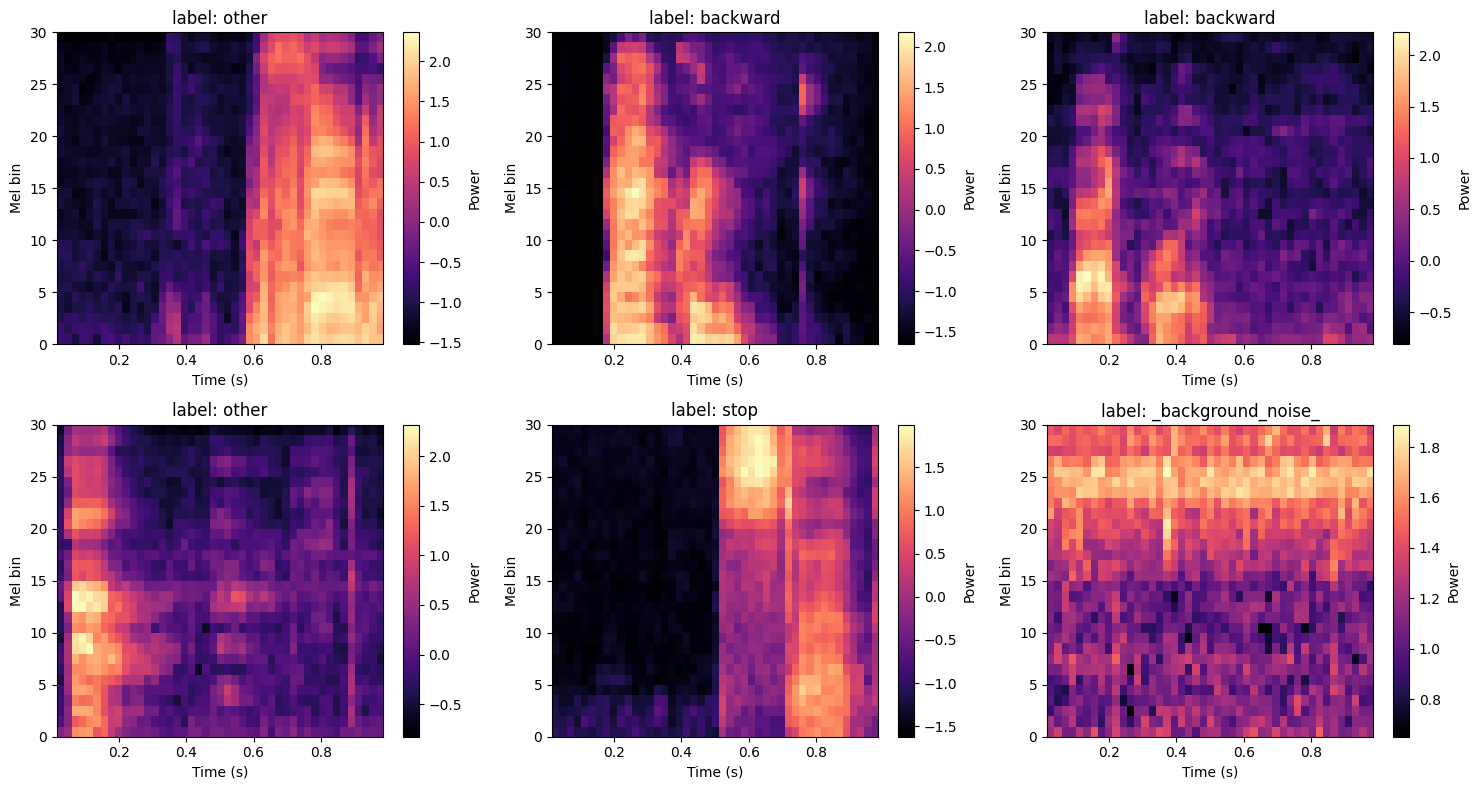

In [14]:
def visualize_dataset_samples(dataset, n_samples=6, label_names=None, seed=None):
    """
    dataset: unbatched tf.data.Dataset yielding (spectrogram, label) pairs,
    as returned by build_spectrogram_dataset(). Call this BEFORE .batch().
    """
    # Shuffle with a buffer covering the full dataset so `take` isn't biased
    # toward whatever ordering the dataset happens to be in (e.g. all
    # background noise first). Since your dataset is small (~10k clips),
    # a full-size buffer is cheap.
    cardinality = dataset.cardinality().numpy()
    buffer_size = cardinality if cardinality > 0 else 10000  # fallback if unknown
    shuffled = dataset.shuffle(buffer_size, seed=seed)

    samples = list(shuffled.take(n_samples).as_numpy_iterator())

    n = len(samples)
    ncols = min(n, 3)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, (spec, label) in zip(axes, samples):
        label_str = label_names[label] if label_names is not None else str(label)
        plot_spectrogram(spec, title=f"label: {label_str}", ax=ax)

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Usage:
visualize_dataset_samples(train_ds, n_samples=6, label_names=label_names, seed=42)

### Calculate Norm Stats

In [15]:
def compute_norm(train_ds):
    norm_layer = layers.Normalization(axis=None)
    norm_layer.adapt(data=train_ds.map(lambda spec, label: spec))

    mean = float(norm_layer.mean.numpy().squeeze())
    variance = float(norm_layer.variance.numpy().squeeze())
    
    return mean, variance

mean, variance = compute_norm(train_ds)

print(f"Mean {mean}, Variance {variance}")

Mean -0.08735589683055878, Variance 0.9006134271621704


## Finalize Dataset

In [16]:
BATCH_SIZE = 1024
SHUFFLE_BUFFER_SIZE = int(train_ds.cardinality())  # whole train set, so the shuffle is uniform

# --- Step 4: Batch/cache/prefetch as usual, downstream of normalization ---
train_ds = (train_ds
    .cache()
    .shuffle(SHUFFLE_BUFFER_SIZE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))

val_ds = val_ds.cache().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.cache().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

## Class Weights

`other` is now the biggest class, and `stop` has about 2.4x as many clips as `forward`. With
`CLASS_WEIGHT_POWER = 1` every class carries the same total weight in the loss, so the extra
`other` clips add variety without outvoting the keywords. 0 turns weighting off.

In [ ]:
CLASS_WEIGHT_POWER = 1.0  # 0 = no weighting, 0.5 = sqrt, 1 = fully balanced

def compute_class_weights(labels, num_classes, power):
    counts = np.bincount(labels, minlength=num_classes)
    weights = (counts.sum() / (num_classes * counts)) ** power
    weights /= weights.mean()  # mean 1 keeps the effective learning rate the same
    return {i: float(w) for i, w in enumerate(weights)}, counts

class_weight, class_counts = compute_class_weights(train_labels, len(label_names), CLASS_WEIGHT_POWER)
for i, name in enumerate(label_names):
    print(f"{name:>20}: {class_counts[i]:6d} clips, weight {class_weight[i]:.3f}")

# Convert Dataset to .npz for ST AI Tools

In [17]:
import numpy as np
import tensorflow as tf

def dataset_to_npz(dataset, output_path, num_classes):
    x_batches = []
    y_batches = []

    for x_batch, y_batch in dataset:
        x_batches.append(x_batch.numpy())
        y_onehot = tf.one_hot(y_batch, num_classes)
        y_batches.append(y_onehot.numpy())

    x_test = np.concatenate(x_batches, axis=0)
    y_test = np.concatenate(y_batches, axis=0)

    np.savez(output_path, x_test=x_test, y_test=y_test)
    return x_test, y_test

x_test, y_test = dataset_to_npz(test_ds, "TestDatasetST/test_ds.npz", num_classes=5)
print(x_test.shape, y_test.shape)

(1048, 30, 45) (1048, 5)


# Model

In [18]:
EPOCHS = 125
INITIAL_LR = 3e-4
LR_ALPHA = 0.0028  # final LR = INITIAL_LR * LR_ALPHA
EARLY_STOP_PATIENCE = 15

def gen_model(epochs):
    steps_per_epoch = tf.data.experimental.cardinality(train_ds).numpy()
    
    decay_steps = epochs * steps_per_epoch
    
    lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=INITIAL_LR,
        decay_steps=decay_steps,
        alpha=LR_ALPHA,
    )
    
    
    for example_spectrograms, example_spect_labels in train_ds.take(1):
      break
    
    input_shape = example_spectrograms.shape[1:]
    print('Input shape:', input_shape)
    num_labels = len(label_names)
    print('Labels: ', label_names)
    
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Reshape(input_shape + (1,)),  # (30, 45) -> (30, 45, 1)

        ##
        # C0
        ##
        
        # Convolutional layer (bias is set to False because BatchNorm adds its own beta bias parameter)
        layers.Conv2D(filters=16, kernel_size=(3, 3), padding='valid', use_bias=False),
        layers.BatchNormalization(),
        
        # Non-linear activation (applied after batch normalization)
        layers.Activation('relu'),
        
        layers.MaxPooling2D(pool_size=(4, 4)),

        ##
        # C1
        ##

        # Convolutional layer (bias is set to False because BatchNorm adds its own beta bias parameter)
        layers.Conv2D(filters=24, kernel_size=(3, 3), padding='valid', use_bias=False),
        layers.BatchNormalization(),

        # Non-linear activation (applied after batch normalization)
        layers.Activation('relu'),

        ##
        # C2
        ##

        # Convolutional layer (bias is set to False because BatchNorm adds its own beta bias parameter)
        layers.Conv2D(filters=24, kernel_size=(3, 3), padding='valid', use_bias=False),
        layers.BatchNormalization(),

        # Non-linear activation (applied after batch normalization)
        layers.Activation('relu'),

        ##
        # Global Pool + Output
        ##
        layers.GlobalMaxPooling2D(),
        
        layers.Dense(num_labels),
    ])

    model.summary()


    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'],
    )

    return model

model = gen_model(EPOCHS)

Input shape: (30, 45)
Labels:  ['forward' 'backward' 'stop' '_background_noise_' 'other']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape (Reshape)               │ (None, 30, 45, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 43, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 43, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 43, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 7, 10, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 8, 24)       │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 8, 24)       │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 5, 8, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 6, 24)       │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 6, 24)       │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 3, 6, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 24)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,165 (35.80 KB)

 Trainable params: 9,037 (35.30 KB)

 Non-trainable params: 128 (512.00 B)

# Train

## Checkpoints

In [19]:
from sklearn.metrics import f1_score, recall_score


class ValClassRecall(tf.keras.callbacks.Callback):
    """Adds validation metrics that weigh every class equally to the epoch logs:
    val_recall_<class>, their mean val_balanced_acc, and val_macro_f1 (for reference).

    val_accuracy is dominated by 'other', the biggest class. val_balanced_acc doesn't
    depend on the class mix, so checkpoints and early stopping use it. Must come
    before the callbacks that read it in the callbacks list.
    """

    def __init__(self, val_ds, label_names):
        super().__init__()
        self.val_ds = val_ds
        self.label_names = label_names
        self.y_true = np.concatenate([y for _, y in val_ds.as_numpy_iterator()])

    def on_epoch_end(self, epoch, logs=None):
        y_pred = np.argmax(self.model.predict(self.val_ds, verbose=0), axis=1)
        labels = np.arange(len(self.label_names))
        recalls = recall_score(self.y_true, y_pred, labels=labels, average=None, zero_division=0)
        for name, recall in zip(self.label_names, recalls):
            logs[f"val_recall_{name.strip('_')}"] = float(recall)
        logs["val_balanced_acc"] = float(recalls.mean())
        logs["val_macro_f1"] = float(f1_score(self.y_true, y_pred, labels=labels,
                                              average="macro", zero_division=0))


# --- Setup ---
checkpoint_dir = f"checkpoints/kws_{MODEL_VERSION}"
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, "model_epoch{epoch:03d}.keras")

# Also keep a "latest" symlink-style path for easy resume
latest_path = os.path.join(checkpoint_dir, "latest.keras")
# Also keep a "best" symlink-style path for easy resume
best_path = os.path.join(checkpoint_dir, "best.keras")


checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    save_weights_only=False,   # saves full model (architecture + weights + optimizer state)
    save_best_only=False,      # set True if you only want to keep the best val_loss/val_acc
    monitor="val_balanced_acc",  # relevant if save_best_only=True
    mode="max",
    save_freq="epoch",
    verbose=1,
)

best_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=best_path,
    save_weights_only=False,   # saves full model (architecture + weights + optimizer state)
    save_best_only=True,      # set True if you only want to keep the best val_loss/val_acc
    monitor="val_balanced_acc",  # from ValClassRecall
    mode="max",
    save_freq="epoch",
    verbose=1,
)

# Optional: always overwrite a single "latest" file too, useful for quick resume
latest_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=latest_path,
    save_weights_only=False,
    save_freq="epoch",
    verbose=0,
)

## Start MLflow Run

In [20]:
def model_summary_text(model):
    chunks = []
    model.summary(print_fn=lambda text, **kwargs: chunks.append(text))
    return "\n".join(chunks)


def build_dataset_manifest():
    """One row per clip: its split, label and split group. Sorted, so the same clips
    always give the same CSV (and hash), whatever order the files were listed in."""
    splits = {
        "train": (train_files, train_labels, all_group_ids[train_idx]),
        "val": (val_files, val_labels, temp_groups[val_sub_idx]),
        "test": (test_files, test_labels, temp_groups[test_sub_idx]),
    }
    manifest = pd.concat([
        pd.DataFrame({"split": split, "file": files, "label": labels,
                      "label_name": label_names[labels], "group_id": groups})
        for split, (files, labels, groups) in splits.items()
    ], ignore_index=True)
    return manifest.sort_values(["split", "file"], ignore_index=True)


# Re-running this cell: mark the previous run as killed instead of logging into it
if mlflow.active_run():
    mlflow.end_run(status="KILLED")
run = mlflow.start_run(run_name=MODEL_VERSION)

if RUN_NOTES:
    mlflow.set_tag("mlflow.note.content", RUN_NOTES)
mlflow.set_tags(git_info())

mlflow.log_params({
    # Preprocessing (must match the firmware)
    "sample_rate_hz": AUDIO_SAMPLE_RATE_HZ,
    "frame_len": AUDIO_SPECTROGRAM_FRAME_LEN,
    "stride_len": AUDIO_SPECTROGRAM_STRIDE_LEN,
    "n_mels": AUDIO_SPECTROGRAM_NMELS,
    "n_frames": AUDIO_SPECTROGRAM_COLS,
    # Dataset
    "class_names": [str(name) for name in label_names],
    "other_clips_per_word": OTHER_CLIPS_PER_WORD,
    "confusable_clips_per_word": CONFUSABLE_CLIPS_PER_WORD,
    "confusable_words": CONFUSABLE_WORDS,
    "split_seed": SPLIT_SEED,
    "synthetic_noise_seconds": SYNTHETIC_NOISE_SECONDS,
    "background_group_seconds": BACKGROUND_GROUP_SECONDS,
    "noise_sources": {name: str(path) for name, path in NOISE_SOURCES.items()},
    "augment": AUGMENT,
    "n_train": len(train_files),
    "n_val": len(val_files),
    "n_test": len(test_files),
    # Training
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "initial_lr": INITIAL_LR,
    "lr_alpha": LR_ALPHA,
    "early_stop_patience": EARLY_STOP_PATIENCE,
    "class_weight_power": CLASS_WEIGHT_POWER,
    "class_weights": {str(name): round(class_weight[i], 3) for i, name in enumerate(label_names)},
    "seed": seed,
    # Model
    "num_params": model.count_params(),
})
mlflow.log_text(model_summary_text(model), "model_summary.txt")

# The audio isn't copied: Speech Commands v0.02 is fixed, dataset_board/ is pinned by
# git_commit and the noise split is rebuilt deterministically. The manifest records
# exactly which clips went into which split.
manifest = build_dataset_manifest()
manifest_csv = manifest.to_csv(index=False)
mlflow.log_text(manifest_csv, "dataset/dataset_manifest.csv")
# Same hash in two runs = exactly the same clips in each split
mlflow.log_param("dataset_manifest_sha256", hashlib.sha256(manifest_csv.encode()).hexdigest())
with warnings.catch_warnings():
    # from_pandas warns that int columns can't hold NaN, which only matters for model schemas
    warnings.simplefilter("ignore", UserWarning)
    for split, split_df in manifest.groupby("split"):
        mlflow.log_input(mlflow.data.from_pandas(split_df, name=f"kws_{split}"), context=split)

print(f"Started MLflow run {run.info.run_id} ({MODEL_VERSION})")

Started MLflow run 0befb3d48f5042f3a17f4f526e8d1676 (v9)


## Train

In [21]:
log_dir = f"logs/fit/{MODEL_VERSION}/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(verbose=1, patience=EARLY_STOP_PATIENCE,
                                                           monitor="val_balanced_acc", mode="max")

# ValClassRecall first: the callbacks after it read val_balanced_acc from the same logs
callbacks = [ValClassRecall(val_ds, label_names), tensorboard_callback, checkpoint_callback,
             latest_callback, best_callback, early_stopping_callback]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/125


2026-10-20 11:48:56.455007: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.2106 - loss: 2.5716
Epoch 1: saving model to checkpoints/kws_v9/model_epoch001.keras

Epoch 1: val_accuracy improved from None to 0.14665, saving model to checkpoints/kws_v9/best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.2282 - loss: 2.4635 - val_accuracy: 0.1467 - val_loss: 1.6219
Epoch 2/125
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3460 - loss: 2.0152
Epoch 2: saving model to checkpoints/kws_v9/model_epoch002.keras

Epoch 2: val_accuracy improved from 0.14665 to 0.16051, saving model to checkpoints/kws_v9/best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.3682 - loss: 1.9557 - val_accuracy: 0.1605 - val_loss: 1.5981
Epoch 3/125
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4539 - loss: 1.6879
Epoch 3: saving model to checkpoints/kws_v9/model_epoch003.keras

Epoch 3: val_accuracy improved from 0.16051 to 0.16166, saving model to checkpoints/kws_v9/best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 52m

## Log Training to MLflow

In [22]:
require_mlflow_run()

mlflow.set_tag("tensorboard_log_dir", log_dir)
for epoch in history.epoch:
    mlflow.log_metrics({name: float(values[epoch]) for name, values in history.history.items()},
                       step=epoch)
mlflow.log_metric("epochs_trained", len(history.epoch))  # < EPOCHS if early stopping kicked in
mlflow.log_artifact(best_path, "models")

## Visualize Training

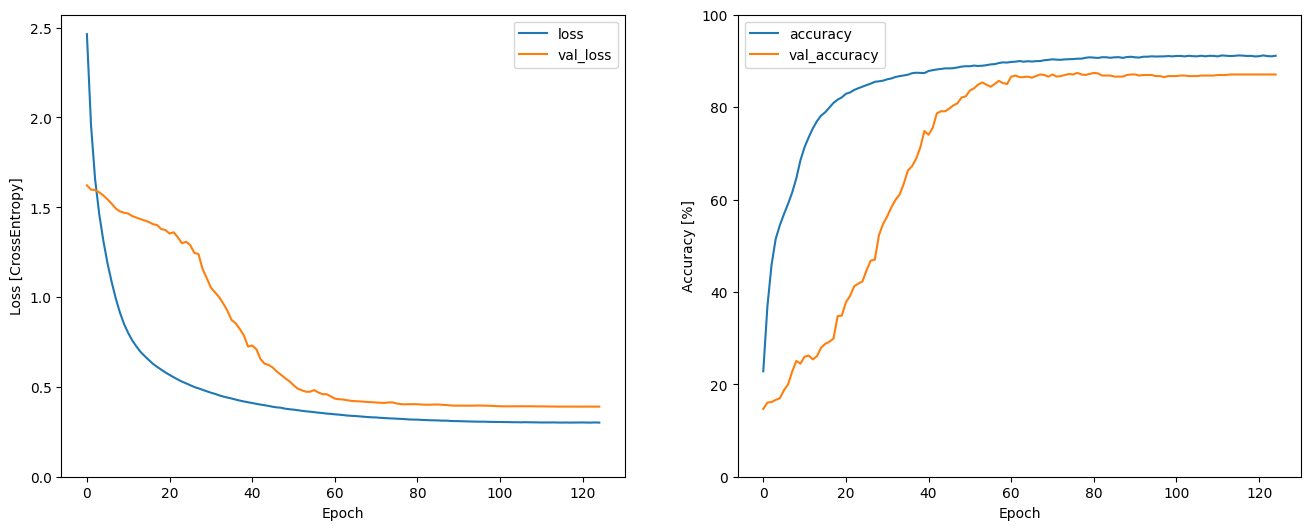

In [23]:
metrics = history.history
plt.figure(figsize=(16,6))
plt.subplot(1,2,1)
plt.plot(history.epoch, metrics['loss'], metrics['val_loss'])
plt.legend(['loss', 'val_loss'])
plt.ylim([0, max(plt.ylim())])
plt.xlabel('Epoch')
plt.ylabel('Loss [CrossEntropy]')

plt.subplot(1,2,2)
plt.plot(history.epoch, 100*np.array(metrics['accuracy']), 100*np.array(metrics['val_accuracy']))
plt.legend(['accuracy', 'val_accuracy'])
plt.ylim([0, 100])
plt.xlabel('Epoch')
plt.ylabel('Accuracy [%]')

require_mlflow_run()
mlflow.log_figure(plt.gcf(), "plots/training_curves.png")

## Restore Best Model

In [24]:
model = tf.keras.models.load_model(best_path)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape (Reshape)               │ (None, 30, 45, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 43, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 43, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 43, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 7, 10, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 8, 24)       │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 8, 24)       │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 5, 8, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 6, 24)       │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 6, 24)       │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 3, 6, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 24)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,240 (106.41 KB)

 Trainable params: 9,037 (35.30 KB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 18,075 (70.61 KB)

## Tensorboard

In [25]:
%tensorboard --logdir logs/fit/{MODEL_VERSION}

# Evaluate

Val Eval
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.8741 - loss: 0.4039
Test Eval
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8588 - loss: 0.4190
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


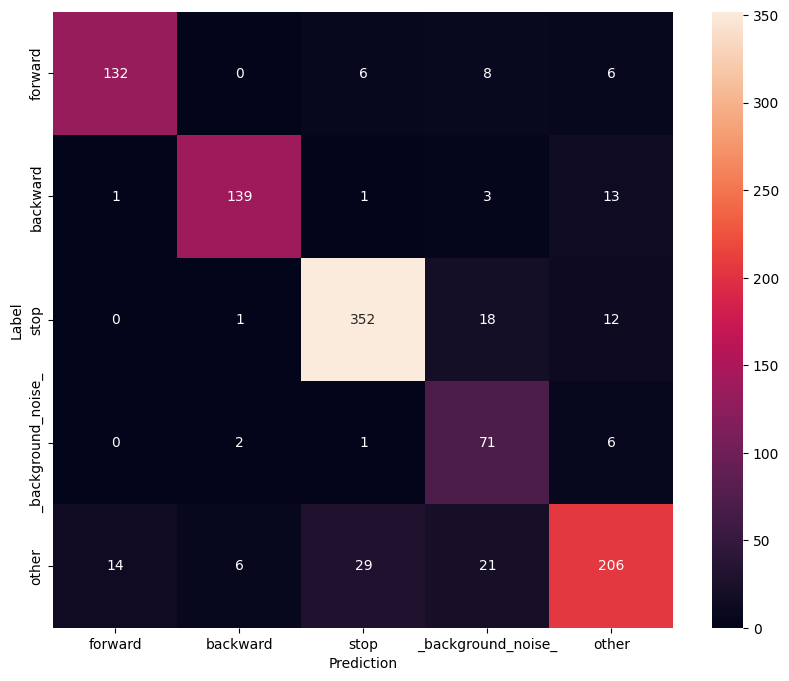

In [26]:
def eval_model():
    print("Val Eval")
    val_metrics = model.evaluate(val_ds, return_dict=True)
    
    print("Test Eval")
    test_metrics = model.evaluate(test_ds, return_dict=True)
    
    y_pred = model.predict(test_ds)
    y_pred = tf.argmax(y_pred, axis=1)
    y_true = tf.concat(list(test_ds.map(lambda s,lab: lab)), axis=0)
    
    confusion_mtx = tf.math.confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(confusion_mtx,
                xticklabels=new_label_names,
                yticklabels=new_label_names,
                annot=True, fmt='g')
    plt.xlabel('Prediction')
    plt.ylabel('Label')
    plt.show()

    return val_metrics, test_metrics

val_metrics, test_metrics = eval_model()

## Log Keras Metrics to MLflow

In [27]:
require_mlflow_run()

mlflow.log_metrics({f"keras_val_{name}": float(value) for name, value in val_metrics.items()})
mlflow.log_metrics({f"keras_test_{name}": float(value) for name, value in test_metrics.items()})

# Quantize

## Add Softmax layer for quantized model

In [28]:
export_model = tf.keras.Sequential([
    model,
    tf.keras.layers.Softmax()
])

## Quantization Aware Training to Fine Tune

In [29]:
# import tensorflow_model_optimization as tfmot

# def gen_qat_model(float_model, qat_epochs, qat_lr=1e-5):
#     """
#     Wraps a trained float model with fake-quant nodes for QAT fine-tuning.
#     tfmot's default8bit scheme recognizes the Conv2D->BatchNorm->ReLU
#     pattern and simulates the folded/fused int8 op during training,
#     matching what the TFLite converter will actually produce.
#     """
#     quantize_model = tfmot.quantization.keras.quantize_model

#     q_aware_model = quantize_model(float_model)

#     steps_per_epoch = tf.data.experimental.cardinality(train_ds).numpy()
#     decay_steps = qat_epochs * steps_per_epoch

#     lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
#         initial_learning_rate=qat_lr,
#         decay_steps=decay_steps,
#         alpha=0.1,
#     )

#     q_aware_model.compile(
#         optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
#         loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
#         metrics=['accuracy'],
#     )

#     q_aware_model.summary()

#     return q_aware_model

In [30]:
# QAT_EPOCHS = 10

# q_aware_model = gen_qat_model(model, qat_epochs=QAT_EPOCHS, qat_lr=1e-5)

# q_aware_history = q_aware_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=QAT_EPOCHS,
# )

## Quantize

In [31]:
def representative_dataset_gen(dataset, num_calibration_steps=200):
    """
    dataset: a batched tf.data.Dataset (e.g. train_ds), already normalized.
    Yields single-example, float32 batches for calibration.
    """
    for spectrogram, _ in dataset.unbatch().take(num_calibration_steps):
        sample = tf.expand_dims(spectrogram, axis=0)
        yield [tf.cast(sample, tf.float32)]


def representative_dataset_gen_stratified(dataset, num_classes,
                                            samples_per_class=40):
    """
    Stratified version: pulls roughly equal samples per class from
    the (already normalized) dataset. Unbatches first since train_ds
    is batched at 1024.
    """
    counts = {i: 0 for i in range(num_classes)}
    target = samples_per_class

    for spectrogram, label in dataset.unbatch():
        label_idx = int(label.numpy())
        if counts[label_idx] < target:
            sample = tf.expand_dims(spectrogram, axis=0)
            yield [tf.cast(sample, tf.float32)]
            counts[label_idx] += 1
        if all(c >= target for c in counts.values()):
            break


def convert_to_tflite_int8(model, representative_dataset_fn, output_path):
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.representative_dataset = representative_dataset_fn

    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    tflite_model = converter.convert()

    with open(output_path, "wb") as f:
        f.write(tflite_model)

    print(f"Saved quantized model to {output_path}")
    print(f"Model size: {len(tflite_model) / 1024:.1f} KB")

    return tflite_model


# --- Usage ---
CALIB_SAMPLES_PER_CLASS = 40
num_labels = len(label_names)

tflite_model = convert_to_tflite_int8(
    model=export_model,
    representative_dataset_fn=lambda: representative_dataset_gen_stratified(
        train_ds, num_classes=num_labels, samples_per_class=CALIB_SAMPLES_PER_CLASS
    ),
    output_path=TFLITE_INT8_PATH,
)

INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpz_mwul75/assets


INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpz_mwul75/assets


Saved artifact at '/var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpz_mwul75'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 45), dtype=tf.float32, name='keras_tensor_105')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  12980089808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976447808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976446400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976444112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976452560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12975885824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980629776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980632240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980621680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980626080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980620096

/Users/gerald/miniconda3/envs/kws/lib/python3.10/site-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1792512375.353705  102549 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1792512375.353727  102549 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-10-20 12:06:15.353952: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpz_mwul75
2026-10-20 12:06:15.354542: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-10-20 12:06:15.354548: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpz_mwul75
I0000 00:00:1792512375.359535  102549 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
2026-10-20 12:06:15.3

Saved quantized model to tflite_models/kws_v9_int8_softmax.tflite
Model size: 15.6 KB


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


## Convert to tflite, no quantize

In [32]:
def convert_to_tflite_float32(model, output_path):
    converter = tf.lite.TFLiteConverter.from_keras_model(model)

    tflite_model = converter.convert()

    with open(output_path, "wb") as f:
        f.write(tflite_model)

    print(f"Saved float32 model to {output_path}")
    print(f"Model size: {len(tflite_model) / 1024:.1f} KB")

    return tflite_model


# --- Usage ---
tflite_float_model = convert_to_tflite_float32(
    model=export_model,
    output_path=TFLITE_FLOAT_PATH,
)

INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp3iqnthel/assets


INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp3iqnthel/assets


Saved artifact at '/var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp3iqnthel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 45), dtype=tf.float32, name='keras_tensor_105')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  12980089808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976447808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976446400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976444112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976452560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12975885824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980629776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980632240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980621680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980626080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980620096

W0000 00:00:1792512375.912515  102549 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1792512375.912524  102549 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-10-20 12:06:15.912622: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp3iqnthel
2026-10-20 12:06:15.913196: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-10-20 12:06:15.913201: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp3iqnthel
2026-10-20 12:06:15.918833: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-10-20 12:06:15.950170: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp3iqnthel
2026-10-20 12:06:15.959862: I tensorflow/cc/saved_model/loader.cc:

## Log Models to MLflow

In [33]:
require_mlflow_run()

mlflow.log_param("calib_samples_per_class", CALIB_SAMPLES_PER_CLASS)
for path in (TFLITE_INT8_PATH, TFLITE_FLOAT_PATH):
    mlflow.log_artifact(path, "models")
mlflow.log_metrics({
    "model_size_kb_int8": os.path.getsize(TFLITE_INT8_PATH) / 1024,
    "model_size_kb_float": os.path.getsize(TFLITE_FLOAT_PATH) / 1024,
})
# Lets the board eval cell check that eval_history.csv scored this exact file
mlflow.set_tag("int8_tflite_sha256", file_sha256(TFLITE_INT8_PATH))

## Validate

### Validate Int8 TFLite

In [34]:
from ai_edge_litert.interpreter import Interpreter

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

def validate_tflite_model(tflite_path, test_ds, label_names):
    """
    Runs the int8 tflite model over test_ds and returns true/predicted
    labels for further analysis (accuracy, confusion matrix, etc).
    """
    interpreter = Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    in_scale, in_zero_point = input_details['quantization']

    y_true = []
    y_pred = []

    for spectrogram, label in test_ds.unbatch():
        x = spectrogram.numpy()
        x_q = (x / in_scale + in_zero_point).round().astype(input_details['dtype'])
        x_q = np.expand_dims(x_q, axis=0)

        interpreter.set_tensor(input_details['index'], x_q)
        interpreter.invoke()
        out_q = interpreter.get_tensor(output_details['index'])[0]

        pred = np.argmax(out_q)  # argmax unaffected by dequantization
        y_pred.append(pred)
        y_true.append(int(label.numpy()))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = (y_true == y_pred).mean()
    print(f"Int8 model accuracy on test set: {accuracy:.4f} ({(y_true == y_pred).sum()}/{len(y_true)})")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=label_names))

    return y_true, y_pred




# --- Usage ---
y_true, y_pred_int8 = validate_tflite_model(TFLITE_INT8_PATH, test_ds, label_names)

Int8 model accuracy on test set: 0.8607 (902/1048)

Classification report:
                    precision    recall  f1-score   support

           forward       0.90      0.87      0.88       152
          backward       0.94      0.89      0.91       157
              stop       0.91      0.92      0.91       383
_background_noise_       0.60      0.89      0.71        80
             other       0.85      0.75      0.79       276

          accuracy                           0.86      1048
         macro avg       0.84      0.86      0.84      1048
      weighted avg       0.87      0.86      0.86      1048



INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
2026-10-20 12:06:16.145010: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### Validate Float TFLite

In [35]:
from ai_edge_litert.interpreter import Interpreter

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

def validate_tflite_model_float(tflite_path, test_ds, label_names):
    """
    Runs the float32 tflite model over test_ds and returns true/predicted
    labels for further analysis (accuracy, confusion matrix, etc).
    """
    interpreter = Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    y_true = []
    y_pred = []

    for spectrogram, label in test_ds.unbatch():
        x = spectrogram.numpy().astype(input_details['dtype'])
        x = np.expand_dims(x, axis=0)

        interpreter.set_tensor(input_details['index'], x)
        interpreter.invoke()
        out = interpreter.get_tensor(output_details['index'])[0]

        pred = np.argmax(out)
        y_pred.append(pred)
        y_true.append(int(label.numpy()))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = (y_true == y_pred).mean()
    print(f"Float model accuracy on test set: {accuracy:.4f} ({(y_true == y_pred).sum()}/{len(y_true)})")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=label_names))

    return y_true, y_pred


# --- Usage ---
y_true, y_pred_float = validate_tflite_model_float(
    TFLITE_FLOAT_PATH, test_ds, label_names
)

Float model accuracy on test set: 0.8588 (900/1048)

Classification report:
                    precision    recall  f1-score   support

           forward       0.90      0.87      0.88       152
          backward       0.94      0.89      0.91       157
              stop       0.90      0.92      0.91       383
_background_noise_       0.59      0.89      0.71        80
             other       0.85      0.75      0.79       276

          accuracy                           0.86      1048
         macro avg       0.84      0.86      0.84      1048
      weighted avg       0.87      0.86      0.86      1048



### Log Test Metrics to MLflow

In [36]:
def log_test_report(prefix, y_true, y_pred):
    """Logs test accuracy and macro/per-class F1 for one model, plus the full report as text."""
    report = classification_report(y_true, y_pred, target_names=label_names, output_dict=True)
    metrics = {
        f"{prefix}_test_accuracy": report["accuracy"],
        f"{prefix}_test_macro_f1": report["macro avg"]["f1-score"],
    }
    for name in label_names:
        metrics[f"{prefix}_test_f1_{name.strip('_')}"] = report[name]["f1-score"]
    mlflow.log_metrics(metrics)
    mlflow.log_text(classification_report(y_true, y_pred, target_names=label_names, digits=4),
                    f"reports/{prefix}_classification_report.txt")


require_mlflow_run()
log_test_report("int8", y_true, y_pred_int8)
log_test_report("float", y_true, y_pred_float)

### Confusion Matrix

#### Confusion Matrix Int8

Saved confusion matrix to /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp38629wsx/confusion_matrix_int8.png


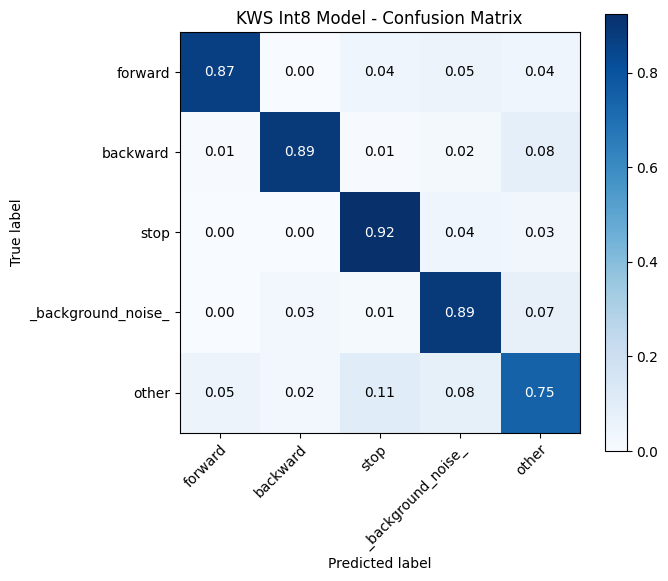

In [37]:
def plot_confusion_matrix(y_true, y_pred, label_names, normalize=True,
                            title="Confusion Matrix", save_path=None):
    """
    Plots a confusion matrix. Set normalize=True to show per-class
    recall (rows sum to 1) rather than raw counts, useful for
    imbalanced classes like your 'background'/'other' vs keyword classes.
    """
    cm = confusion_matrix(y_true, y_pred)
    if normalize:
        cm_display = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)
        fmt = ".2f"
    else:
        cm_display = cm
        fmt = "d"

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_display, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(label_names)),
        yticks=np.arange(len(label_names)),
        xticklabels=label_names,
        yticklabels=label_names,
        ylabel='True label',
        xlabel='Predicted label',
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    thresh = cm_display.max() / 2.0
    for i in range(cm_display.shape[0]):
        for j in range(cm_display.shape[1]):
            ax.text(
                j, i, format(cm_display[i, j], fmt),
                ha="center", va="center",
                color="white" if cm_display[i, j] > thresh else "black",
            )

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved confusion matrix to {save_path}")
    plt.show()

    return cm

require_mlflow_run()
with tempfile.TemporaryDirectory() as tmp_dir:
    cm_path = os.path.join(tmp_dir, "confusion_matrix_int8.png")
    cm = plot_confusion_matrix(y_true, y_pred_int8, label_names, normalize=True,
                                 title="KWS Int8 Model - Confusion Matrix", save_path=cm_path)
    mlflow.log_artifact(cm_path, "plots")

#### Confusion Matrix Float Model

Saved confusion matrix to /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmp0df8ccwj/confusion_matrix_float.png


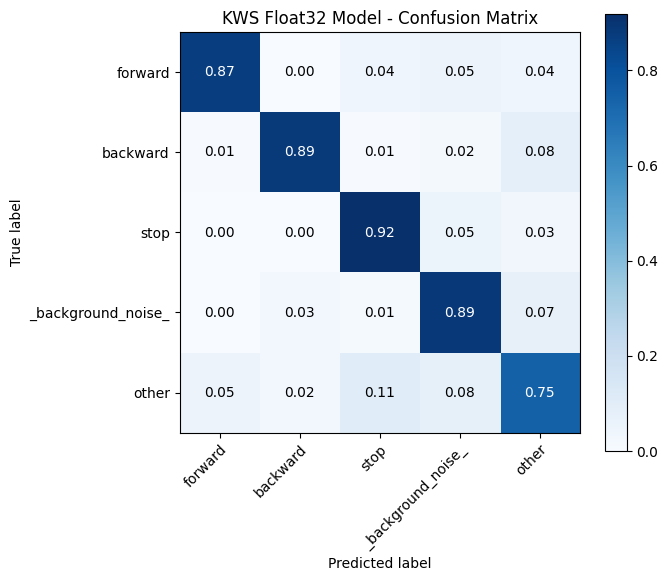

In [38]:
def plot_confusion_matrix(y_true, y_pred, label_names, normalize=True,
                            title="Confusion Matrix", save_path=None):
    """
    Plots a confusion matrix. Set normalize=True to show per-class
    recall (rows sum to 1) rather than raw counts, useful for
    imbalanced classes like your 'background'/'other' vs keyword classes.
    """
    cm = confusion_matrix(y_true, y_pred)
    if normalize:
        cm_display = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)
        fmt = ".2f"
    else:
        cm_display = cm
        fmt = "d"

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_display, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(label_names)),
        yticks=np.arange(len(label_names)),
        xticklabels=label_names,
        yticklabels=label_names,
        ylabel='True label',
        xlabel='Predicted label',
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    thresh = cm_display.max() / 2.0
    for i in range(cm_display.shape[0]):
        for j in range(cm_display.shape[1]):
            ax.text(
                j, i, format(cm_display[i, j], fmt),
                ha="center", va="center",
                color="white" if cm_display[i, j] > thresh else "black",
            )

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved confusion matrix to {save_path}")
    plt.show()

    return cm

require_mlflow_run()
with tempfile.TemporaryDirectory() as tmp_dir:
    cm_path = os.path.join(tmp_dir, "confusion_matrix_float.png")
    cm = plot_confusion_matrix(y_true, y_pred_float, label_names, normalize=True,
                                 title="KWS Float32 Model - Confusion Matrix", save_path=cm_path)
    mlflow.log_artifact(cm_path, "plots")

## Save Quantized Dataset

In [39]:
import numpy as np
import tensorflow as tf
from ai_edge_litert.interpreter import Interpreter

def dataset_to_quantized_npz(dataset, tflite_path, output_path):
    """
    Quantizes both input features and one-hot ground-truth targets according to 
    the TFLite model's input/output quantization parameters and tensor shapes 
    for ST Edge AI Studio validation.
    """
    # Load interpreter and extract details
    interpreter = Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    # Input quantization parameters
    in_scale, in_zero_point = input_details['quantization']
    in_dtype = input_details['dtype']
    in_info = np.iinfo(in_dtype)

    # Output quantization parameters and shape details
    out_scale, out_zero_point = output_details['quantization']
    out_dtype = output_details['dtype']
    out_shape = output_details['shape']  # e.g., [1, 1, 1, 5]
    num_classes = out_shape[-1]          # Last dimension is the class count (e.g., 5)

    print(f"In scale {in_scale}, in zp {in_zero_point}, out scale {out_scale}, out zp {out_zero_point}")
    print(f"Model output tensor shape per sample: {out_shape[1:]}, num_classes: {num_classes}")

    x_batches = []
    y_batches = []

    for x_batch, y_batch in dataset:
        # --- 1. Quantize Inputs (x) ---
        x_np = x_batch.numpy()
        x_quantized = np.round(x_np / in_scale + in_zero_point)
        x_quantized = np.clip(x_quantized, in_info.min, in_info.max).astype(in_dtype)
        x_batches.append(x_quantized)

        # --- 2. One-Hot Encode & Quantize Targets (y) ---
        # Convert sparse class indices (0-4) to one-hot float representation (0.0 / 1.0)
        y_onehot = tf.one_hot(y_batch, depth=num_classes).numpy()

        if out_scale != 0:
            out_info = np.iinfo(out_dtype)
            y_quantized = np.round(y_onehot / out_scale + out_zero_point)
            y_quantized = np.clip(y_quantized, out_info.min, out_info.max).astype(out_dtype)
        else:
            y_quantized = y_onehot.astype(out_dtype)

        y_batches.append(y_quantized)

    x_test_quant = np.concatenate(x_batches, axis=0)
    y_test_quant = np.concatenate(y_batches, axis=0)

    # --- 3. Reshape y_test to match Model Output Shape ---
    # Converts shape from (N, num_classes) -> (N, 1, 1, num_classes) or matching output_details
    target_y_shape = (-1,) + tuple(out_shape[1:])
    y_test_quant = y_test_quant.reshape(target_y_shape)

    # Save to compressed file
    np.savez_compressed(output_path, x_test=x_test_quant, y_test=y_test_quant)

    print(f"Saved to: {output_path}")
    print(f"x_test shape: {x_test_quant.shape}, dtype: {x_test_quant.dtype}")
    print(f"y_test shape: {y_test_quant.shape}, dtype: {y_test_quant.dtype}")

    return x_test_quant, y_test_quant


# Usage
x_q, y_t = dataset_to_quantized_npz(
    dataset=test_ds,
    tflite_path=TFLITE_INT8_PATH,
    output_path=f"TestDatasetST/test_ds_int8_kws_{MODEL_VERSION}.npz",
)

In scale 0.018146447837352753, in zp -37, out scale 0.00390625, out zp -128
Model output tensor shape per sample: [5], num_classes: 5
Saved to: TestDatasetST/test_ds_int8_kws_v9.npz
x_test shape: (1048, 30, 45), dtype: int8
y_test shape: (1048, 5), dtype: int8


# Board Eval

Scores the int8 model on the labelled board recordings in `eval_recordings/` with
`snapshot_eval.py` and appends the result to `eval_recordings/eval_history.csv` (the source of
truth). The second cell then copies the pooled `ALL` row into this run, so host and board
numbers show up side by side.

To try other detection settings, run the script from the command line instead and then just the
second cell, which logs the latest snapshot of `MODEL_VERSION`. From `HostSW/`:

```
python EvalScripts/snapshot_eval.py -v <MODEL_VERSION> -m tflite_models/kws_<MODEL_VERSION>_int8_softmax.tflite --threshold 0.6
```

That also works after the run has ended or the kernel was restarted: run the first cell and the
MLflow Tracking cell first.

In [40]:
import sys

# The eval scripts are in HostSW/EvalScripts
if os.path.abspath("EvalScripts") not in sys.path:
    sys.path.insert(0, os.path.abspath("EvalScripts"))
import snapshot_eval

# replace=True: the notebook just (re)trained MODEL_VERSION, so an existing snapshot of it
# with the same settings scored an older model
board_all_row = snapshot_eval.snapshot_eval(MODEL_VERSION, TFLITE_INT8_PATH, notes=RUN_NOTES, replace=True)

eval_01_speech.wav:
  recall 12/15 (80%), false accepts 0 (0.00/min)
eval_02_script.wav:
  recall 27/40 (68%), false accepts 8 (1.71/min)

v9 (2 recordings, avg 0.5s, threshold 0.7, suppress 1.5s):
  recall 39/55 (71%)  forward 62%  backward 69%  stop 83%
  false accepts 8 in 5.5 min = 1.44/min (87/hour)

Previous snapshots (ALL rows; recordings may differ between snapshots):
  2026-10-17T13:45:23  v7       avg 0.5 thr 0.7 sup 1.5  recall 67%  FA 1.08/min  baseline: Speech Commands only, no augmentation

Appended 3 rows to /Users/gerald/SoftwareProjects/KeywordSpottingFWAI/HostSW/eval_recordings/eval_history.csv


In [41]:
EVAL_HISTORY_CSV = "eval_recordings/eval_history.csv"
BOARD_KEYWORDS = ["forward", "backward", "stop"]


def log_board_eval(model_version, history_csv=EVAL_HISTORY_CSV):
    """Logs the latest snapshot_eval.py result for model_version into its MLflow run.

    Logs through MlflowClient with the run id, so it works whether the run has ended or not.
    """
    runs = mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT],
        filter_string=f"tags.mlflow.runName = '{model_version}'",
        order_by=["start_time DESC"],
        max_results=1,
        output_format="list",
    )
    if not runs:
        raise RuntimeError(f"No MLflow run named {model_version}")
    run = runs[0]
    run_id = run.info.run_id

    # dtype=str: a hash prefix that happens to be all digits would otherwise be read as a number
    history = pd.read_csv(history_csv, dtype={"model_sha256": str})
    rows = history[history["model_version"] == model_version]
    if rows.empty:
        raise RuntimeError(f"No rows for {model_version} in {history_csv}: run snapshot_eval.py first")
    # Several snapshots (different detection settings) can exist per version: use the latest
    snapshot = rows[rows["timestamp"] == rows["timestamp"].max()]
    all_row = snapshot[snapshot["recording"] == "ALL"].iloc[0]

    # snapshot_eval.py stores the first 12 hex digits of the tflite's sha256
    run_sha = run.data.tags.get("int8_tflite_sha256", "")
    if not run_sha.startswith(all_row["model_sha256"]):
        raise RuntimeError(
            f"{history_csv} scored {all_row['model_path']} (sha256 {all_row['model_sha256']}), "
            f"but run {run_id} logged an int8 model with sha256 {run_sha[:12] or '(none)'}. "
            "Re-run snapshot_eval.py with --replace for this model."
        )

    client = mlflow.MlflowClient()
    metrics = {
        "board_recall": all_row["recall"],
        "board_fa_per_hour": all_row["fa_per_hour"],
        "board_false_accepts": all_row["false_accepts"],
        "board_substitutions": all_row["substitutions"],
        "board_negative_min": all_row["negative_min"],
    }
    for kw in BOARD_KEYWORDS:
        metrics[f"board_recall_{kw}"] = all_row[f"recall_{kw}"]
    for name, value in metrics.items():
        client.log_metric(run_id, name, float(value))

    # Detection settings as tags, not params: params can't change, and a later snapshot
    # with different settings should replace these
    for key in ["stride_s", "avg_s", "threshold", "suppress_s", "tolerance_s"]:
        client.set_tag(run_id, f"board_{key}", str(all_row[key]))
    client.set_tag(run_id, "board_eval_timestamp", all_row["timestamp"])

    with tempfile.TemporaryDirectory() as tmp_dir:
        csv_path = os.path.join(tmp_dir, "board_eval.csv")
        rows.to_csv(csv_path, index=False)
        client.log_artifact(run_id, csv_path, "reports")

    print(f"Logged board eval from {all_row['timestamp']} to run {run_id}:")
    for name, value in metrics.items():
        print(f"  {name}: {value}")


log_board_eval(MODEL_VERSION)

Logged board eval from 2026-10-20T12:06:16 to run 0befb3d48f5042f3a17f4f526e8d1676:
  board_recall: 0.7091
  board_fa_per_hour: 86.5699
  board_false_accepts: 8
  board_substitutions: 0
  board_negative_min: 5.5447
  board_recall_forward: 0.619
  board_recall_backward: 0.6875
  board_recall_stop: 0.8333


# End MLflow Run

In [42]:
# Ends the run started in 'Start MLflow Run'. Do this, and stop `mlflow ui`, before
# committing mlflow/ (see mlflow/README.md).
mlflow.end_run()

# Compare TFLite vs Keras

## Compare outputs

In [43]:
def compare_keras_vs_tflite(keras_model, tflite_path, test_ds, n=10, seed=None):
    interpreter = Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    # Shuffle with a buffer covering the full dataset so the sample
    # isn't biased toward whatever class appears first in storage order.
    unbatched = test_ds.unbatch()
    total = unbatched.cardinality().numpy()
    if total < 0:  # cardinality unknown (e.g. after certain ops)
        total = sum(1 for _ in unbatched)

    sampled = unbatched.shuffle(buffer_size=total, seed=seed).take(n)

    for i, (spectrogram, label) in enumerate(sampled):
        x_np = spectrogram.numpy()
        # print(f'X_np shape {x_np.shape}')
        # x_np_expanded = np.expand_dims(x_np, axis=0)
        # print(f'X_np_exp shape {x_np_expanded.shape}')


        # Keras
        keras_out = keras_model.predict(np.expand_dims(x_np, axis=0), verbose=0)[0]
        keras_pred = np.argmax(keras_out)

        # TFLite
        x = np.expand_dims(x_np.astype(input_details['dtype']), axis=0)
        interpreter.set_tensor(input_details['index'], x)
        interpreter.invoke()
        tflite_out = interpreter.get_tensor(output_details['index'])[0]
        tflite_pred = np.argmax(tflite_out)

        match = "OK" if keras_pred == tflite_pred else "MISMATCH"
        print(f"[{i}] true={int(label.numpy())} keras_pred={keras_pred} "
              f"tflite_pred={tflite_pred} {match}")
        print(f"    keras_out={keras_out}")
        print(f"    tflite_out={tflite_out}")

compare_keras_vs_tflite(model, TFLITE_FLOAT_PATH, test_ds, n=10)

[0] true=4 keras_pred=3 tflite_pred=3 OK
    keras_out=[-1.1016185  -0.60026634  0.01240348  1.7796208  -0.72265786]
    tflite_out=[0.04000854 0.06605215 0.12188948 0.7136069  0.05844298]
[1] true=4 keras_pred=4 tflite_pred=4 OK
    keras_out=[-1.3876281 -1.321242   1.5843954 -2.047776   2.8137798]
    tflite_out=[0.01124897 0.01202108 0.2197081  0.00581317 0.7512087 ]
[2] true=0 keras_pred=0 tflite_pred=0 OK
    keras_out=[ 1.938229  -2.6142325 -0.6465808 -2.3608196 -0.1988951]
    tflite_out=[0.82133716 0.0086579  0.06193734 0.01115497 0.09691266]
[3] true=1 keras_pred=1 tflite_pred=1 OK
    keras_out=[-1.2517449  3.032242  -2.3348114 -3.5249977 -1.861945 ]
    tflite_out=[0.01342032 0.9733636  0.00454353 0.00138198 0.00729049]
[4] true=2 keras_pred=2 tflite_pred=2 OK
    keras_out=[-3.1319232  -2.5348713   3.2099643  -1.331767    0.11623182]
    tflite_out=[0.00165981 0.00301547 0.9425537  0.01004286 0.04272825]
[5] true=2 keras_pred=2 tflite_pred=2 OK
    keras_out=[-2.597506   -4

## Compare layer by layer

In [44]:
def build_truncated_model(model, up_to_layer_idx):
    """Returns a new Keras model outputting up to and including layer index."""
    model = tf.keras.Model(inputs=model.inputs, outputs=model.layers[up_to_layer_idx].output)
    model.summary()
    return model

def convert_and_run_truncated(model, up_to_layer_idx, x_batch):
    truncated_model = build_truncated_model(model, up_to_layer_idx)
    converter = tf.lite.TFLiteConverter.from_keras_model(truncated_model)
    tflite_model = converter.convert()


    interpreter = Interpreter(model_content=tflite_model)
    interpreter.allocate_tensors()
    in_d = interpreter.get_input_details()[0]
    out_d = interpreter.get_output_details()[0]
    interpreter.set_tensor(in_d['index'], x_batch.astype(in_d['dtype']))
    interpreter.invoke()
    tflite_out = interpreter.get_tensor(out_d['index'])

    keras_out = truncated_model.predict(x_batch, verbose=0)

    max_diff = np.abs(keras_out.astype(np.float64) - tflite_out.astype(np.float64)).max()
    return max_diff, keras_out, tflite_out

for x_batch_tf, _ in test_ds.take(1):
    x_batch = x_batch_tf.numpy().astype(np.float32)
    
# x_batch = np.expand_dims(x_batch, axis=0)
# print(x_batch.shape)

for i, layer in enumerate(model.layers):
    max_diff, keras_out, tflite_out = convert_and_run_truncated(model, i, x_batch[:1])
    print(f"Layer {i} ({layer.name}): max abs diff = {max_diff:.6f}")

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 45)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 30, 45, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

...

INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpeigdfbv7/assets


INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpeigdfbv7/assets


Saved artifact at '/var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpeigdfbv7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 45), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  12980089808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976447808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976446400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976444112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976452560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12975885824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980629776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980632240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980621680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980626080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980620096: Ten

W0000 00:00:1792512383.104344  102549 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1792512383.104353  102549 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-10-20 12:06:23.104461: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpeigdfbv7
2026-10-20 12:06:23.105022: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-10-20 12:06:23.105027: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpeigdfbv7
2026-10-20 12:06:23.110675: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-10-20 12:06:23.141743: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpeigdfbv7
2026-10-20 12:06:23.151765: I tensorflow/cc/saved_model/loader.cc:

Layer 12 (dense): max abs diff = 0.000002


## Compare Problem Layer

In [45]:
i = 6

max_diff, keras_out, tflite_out = convert_and_run_truncated(model, i, x_batch[:1])
print(f"Layer {i} ({layer.name}): max abs diff = {max_diff:.6f}")
print(f"Keras out {keras_out}\n tflite out {tflite_out}")

Model: "functional_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 45)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 30, 45, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 43, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 43, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 43, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 7, 10, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 8, 24)       │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 8, 24)       │            96 │
│ (BatchNormalization)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,760 (14.69 KB)

 Trainable params: 3,680 (14.38 KB)

 Non-trainable params: 80 (320.00 B)

INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpzqbvn9x1/assets


INFO:tensorflow:Assets written to: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpzqbvn9x1/assets


Saved artifact at '/var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpzqbvn9x1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 45), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 5, 8, 24), dtype=tf.float32, name=None)
Captures:
  12980089808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976447808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976446400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976444112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12976452560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12975885824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980629776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980632240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980621680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  12980626080: TensorSpec(shape=(), dtype=tf.resource, name=None)
Layer 6 (de

W0000 00:00:1792512383.464250  102549 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1792512383.464259  102549 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-10-20 12:06:23.464360: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpzqbvn9x1
2026-10-20 12:06:23.464762: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-10-20 12:06:23.464767: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpzqbvn9x1
2026-10-20 12:06:23.468601: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-10-20 12:06:23.489192: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/kx/nq6hh4rj4x12kh104nvwt1hr0000gp/T/tmpzqbvn9x1
2026-10-20 12:06:23.495828: I tensorflow/cc/saved_model/loader.cc:

# Optimize

Optuna architecture search. Slow, so it only runs with `RUN_OPTIMIZE = True` (first cell).

## Study

In [46]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import f1_score
import optuna
import matplotlib.pyplot as plt

INPUT_SHAPE = (30, 45)
NUM_LABELS = 5


def conv_out_dim(size, kernel, padding):
    if padding == 'same':
        return size
    return size - kernel + 1


def compute_conv_macs(h_in, w_in, c_in, filters, kernel, padding):
    h_out = conv_out_dim(h_in, kernel, padding)
    w_out = conv_out_dim(w_in, kernel, padding)
    macs = h_out * w_out * filters * kernel * kernel * c_in
    return macs, h_out, w_out


def baseline_macs():
    macs = 0
    h, w, c = 30, 45, 1
    for i in range(3):
        m, h, w = compute_conv_macs(h, w, c, 48, 3, 'same')
        macs += m
        c = 48
        if i == 0:
            # Max pool 4,4 after C0
            h, w = h // 4, w // 4

    # Dense output layer
    macs += c * NUM_LABELS
    
    return macs


BASELINE_MACS = baseline_macs()
print(f"Baseline MACCs {BASELINE_MACS}")


def build_model_and_macs(trial):
    h, w, c = INPUT_SHAPE[0], INPUT_SHAPE[1], 1
    n_layers = trial.suggest_int('n_conv_layers', 2, 4)

    model = models.Sequential()
    model.add(layers.Input(shape=INPUT_SHAPE))
    model.add(layers.Reshape(INPUT_SHAPE + (1,)))

    total_macs = 0
    for i in range(n_layers):
        filters = trial.suggest_categorical(f'filters_{i}', [16, 24, 32, 48])
        kernel = 3
        padding = 'valid'

        macs, h_out, w_out = compute_conv_macs(h, w, c, filters, kernel, padding)
        if h_out <= 0 or w_out <= 0:
            raise optuna.TrialPruned(f"layer {i}: {padding} kernel={kernel} collapses {h}x{w} to {h_out}x{w_out}")

        model.add(layers.Conv2D(filters=filters, kernel_size=kernel, padding=padding, use_bias=False))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))

        total_macs += macs
        h, w, c = h_out, w_out, filters

        pool = trial.suggest_categorical(f'pool_{i}', [1, 2, 4])
        if pool > 1:
            if h // pool < 1 or w // pool < 1:
                raise optuna.TrialPruned(f"layer {i}: pool={pool} collapses {h}x{w} to 0")
            model.add(layers.MaxPooling2D(pool_size=(pool, pool)))
            h, w = h // pool, w // pool

    model.add(layers.GlobalMaxPooling2D())
    model.add(layers.Dense(NUM_LABELS))
    total_macs += c * NUM_LABELS

    return model, total_macs


def macro_f1_on(model, val_ds):
    y_true = np.concatenate([y.numpy() for _, y in val_ds], axis=0)
    y_pred = np.argmax(model.predict(val_ds, verbose=0), axis=1)
    return f1_score(y_true, y_pred, average='macro')


def objective(trial, train_ds, val_ds):
    EPOCHS = 90

    model, macs = build_model_and_macs(trial)

    lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=3e-4, decay_steps=EPOCHS * len(train_ds), alpha=0.0028
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr_schedule),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy'],
    )

    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor='val_accuracy', patience=15, restore_best_weights=True
            ),
        ],
        verbose=0,
    )

    macro_f1 = macro_f1_on(model, val_ds)
    num_params = model.count_params()

    trial.set_user_attr('macs', macs)
    trial.set_user_attr('macs_ratio', macs / BASELINE_MACS)
    trial.set_user_attr('num_params', num_params)
    trial.set_user_attr('macro_f1', macro_f1)

    return macro_f1, macs, num_params


if not RUN_OPTIMIZE:
    print("Skipped: RUN_OPTIMIZE is False")
else:
    sampler = optuna.samplers.TPESampler(multivariate=True, group=True)
    study = optuna.create_study(
        directions=['maximize', 'minimize', 'minimize'],
        sampler=sampler,
    )
    study.optimize(lambda t: objective(t, train_ds, val_ds), n_trials=100)

Baseline MACCs 3776784
Skipped: RUN_OPTIMIZE is False


In [47]:
if not RUN_OPTIMIZE:
    print("Skipped: RUN_OPTIMIZE is False")
else:
    study.optimize(lambda t: objective(t, train_ds, val_ds), n_trials=70)

Skipped: RUN_OPTIMIZE is False


## Plot Results

In [48]:
if not RUN_OPTIMIZE:
    print("Skipped: RUN_OPTIMIZE is False")
else:
    # Pareto-optimal trials
    pareto = study.best_trials
    print(f"Baseline MACs: {BASELINE_MACS:,}")
    for t in sorted(pareto, key=lambda t: t.values[0], reverse=True):
        print(f"trial {t.number}: macro_f1={t.values[0]:.4f}, "
              f"macs_ratio={t.user_attrs['macs_ratio']:.3f}, params={t.values[2]:,}")
        print(t.params)

    # 3-objective pareto front, sized/colored by the third objective
    from optuna.visualization.matplotlib import plot_pareto_front
    plot_pareto_front(study, target_names=['macro_f1', 'macs', 'num_params'])
    plt.tight_layout()
    plt.show()

Skipped: RUN_OPTIMIZE is False


## Save Results

In [49]:
if not RUN_OPTIMIZE:
    print("Skipped: RUN_OPTIMIZE is False")
else:
    df = study.trials_dataframe()

    df.to_csv('Studies/study_4.csv', index=False)

Skipped: RUN_OPTIMIZE is False
